# Building a Multi Layer Perceptron for Diabetes Risk Prediction

Welcome to your Deep Learning project! In this notebook, you’ll take on the role of a data scientist building a neural network that predicts diabetes risk, helping healthcare providers prioritize patients for diagnostic testing.

### What you'll build

By completing this notebook, you will _(demonstrate ability to)_:

- Design MLP architectures with appropriate depth, width, and activations
- Preprocess data with proper splitting, normalization, and batching
- Implement training loops with forward/backward passes and optimization
- Apply evaluation metrics suited for specialized applications
- Diagnose overfitting/underfitting using loss curves
- Improve models systematically through hyperparameter tuning and regularization
- Interpret performance in context with actionable recommendations

**Dataset**: [CDC Diabetes Health Indicators](https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset) (balanced subset of 50,000 patients, 21 features)  
**Estimated time**: 5-6 hours  

> *Have more questions about the project?* Review the [README.md](../README.md) for full project context, setup instructions, and deliverables.

### Ready to get started?

This notebook is divided into 8 sections: 

```Setup → Data Loading → Data Preprocessing → Model Design → Model Training → Model Evaluation → Model Improvements → Conclusion```

Follow them in sequence to complete your project!

---
## Step 0: Set up the environment

Let's begin by importing the necessary libraries and setting up our environment for reproducibility.

In [1]:
# Standard library imports
import numpy as np
import pandas as pd
import numbers
import copy
import random
import warnings
from pathlib import Path
from time import perf_counter
from IPython.display import display, Markdown
import matplotlib.pyplot as plt
from typing import Dict, Tuple, List, Optional

# PyTorch imports
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

# Scikit-learn imports
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn import metrics

# Set style for better-looking plots
plt.style.use('seaborn-v0_8-darkgrid')

print("All libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")

All libraries imported successfully!
PyTorch version: 2.5.1+cu121


In [2]:
# Set random seeds for reproducibility
# This ensures that your results are consistent across runs
RANDOM_SEED = 42

torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)
torch.set_num_threads(min(4, torch.get_num_threads()))
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)
    
print(f"Random seed set to {RANDOM_SEED}")

Random seed set to 42


> **Why reproducibility matters**: Setting random seeds ensures that your results are consistent across different runs. This is critical for debugging and comparing different model configurations. 
> <br>In production systems, reproducibility helps with model versioning and validation.

In [3]:
# Use GPU if available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    # Set cuDNN to deterministic mode for reproducibility
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

Using device: cuda
GPU: Tesla T4


> **Moving execution to device**: Transferring your model and tensors to the GPU can drastically improve performance.  
> <br>Use `.to(device)` for models and tensors to ensure everything runs on the same hardware.  
> <br>*Example:*  
> ```model = model.to(device)```   
> ```inputs = inputs.to(device)```  
> <br>**Note**: Mixing CPU and GPU tensors in operations will raise errors.

---
## Step 1: Load and explore the dataset

Understanding your data is the first critical step in any deep learning project. In this step, you will load the dataset and perform exploratory data analysis to understand your dataset.

Place `diabetes_data.csv` beside this notebook (as supplied here), or in a `data/` subdirectory. The loading cell checks both locations and raises an explicit error if neither exists. You'll use [pandas](https://pandas.pydata.org/) to load it into a DataFrame for analysis.

### 1.1 Load the dataset

The dataset contains health indicators from the CDC's Behavioral Risk Factor Surveillance System. Each row represents a patient with 21 health-related features and a binary diabetes diagnosis.

In [4]:
# Load the diabetes dataset
data_path = next((path for path in [Path('diabetes_data.csv'), Path('data/diabetes_data.csv')]
                  if path.is_file()), None)
if data_path is None:
    raise FileNotFoundError('Place diabetes_data.csv beside this notebook or in its data/ directory.')
df = pd.read_csv(data_path)
TARGET = 'Diabetes_binary'
if TARGET not in df.columns or df[TARGET].isna().any() or set(df[TARGET].unique()) != {0, 1}:
    raise ValueError('Diabetes_binary must contain both binary classes, without missing labels.')
if not all(pd.api.types.is_numeric_dtype(dtype) for dtype in df.dtypes):
    raise ValueError('This pipeline expects numeric CDC survey features.')
if not np.isfinite(df.to_numpy(dtype=float)).all():
    raise ValueError('Missing or nonfinite values require cleaning before training.')

print(f"Dataset loaded successfully!")
print(f"Dataset shape: {df.shape}")
print(f"\nFirst few rows:")
df.head()

Dataset loaded successfully!
Dataset shape: (50000, 22)

First few rows:


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
0,1,1,1,27,1,0,0,1,0,1,...,0,2,0,0,0,1,12,6,8,1
1,0,0,1,30,0,0,0,1,1,1,...,0,1,0,0,0,1,8,5,5,0
2,1,0,1,33,0,0,0,1,1,1,...,0,3,0,0,0,0,7,5,6,0
3,1,1,1,25,0,0,0,1,1,1,...,0,1,0,0,0,1,9,6,4,0
4,1,1,1,29,1,0,1,0,0,1,...,0,5,3,10,1,0,9,4,2,1


In [5]:
# Implementation 1: Display basic dataset information
# HINT: You need to inspect the DataFrame's structure to understand what columns exist, 
#       their data types, and whether any values are missing. Pandas DataFrames have 
#       methods that provide a concise summary of this information in a single call.
#       Think about what you'd need to know before preprocessing the data.
# REFERENCE: https://pandas.pydata.org/docs/reference/frame.html
# This will help you understand the structure of your data before preprocessing

print('Shape:', df.shape)
print('Columns:', df.columns.tolist())
df.info()
display(df.dtypes.to_frame('dtype'))

Shape: (50000, 22)
Columns: ['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income', 'Diabetes_binary']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   HighBP                50000 non-null  int64
 1   HighChol              50000 non-null  int64
 2   CholCheck             50000 non-null  int64
 3   BMI                   50000 non-null  int64
 4   Smoker                50000 non-null  int64
 5   Stroke                50000 non-null  int64
 6   HeartDiseaseorAttack  50000 non-null  int64
 7   PhysActivity          50000 non-null  int64
 8   Fruits                50000 non-null  int64
 9   Veggies               50000 non-null  i

,dtype
HighBP,int64
HighChol,int64
CholCheck,int64
BMI,int64
Smoker,int64
Stroke,int64
HeartDiseaseorAttack,int64
PhysActivity,int64
Fruits,int64
Veggies,int64


### 1.2 Understanding the features

The dataset contains 21 health and lifestyle indicators. Let's examine what each feature represents and its clinical significance:

| Feature | Description | Type | Clinical Significance |
|---------|-------------|------|----------------------|
| **Diabetes_binary** | Diabetes diagnosis | Binary (0/1) | **Target variable** |
| HighBP | High blood pressure diagnosis | Binary | Strong risk factor |
| HighChol | High cholesterol diagnosis | Binary | Cardiovascular risk |
| CholCheck | Cholesterol check in past 5 years | Binary | Preventive care indicator |
| BMI | Body Mass Index | Continuous | Key obesity indicator |
| Smoker | Smoking history | Binary | Lifestyle risk factor |
| Stroke | History of stroke | Binary | Cardiovascular complication |
| HeartDiseaseorAttack | Coronary heart disease or MI | Binary | Cardiovascular complication |
| PhysActivity | Physical activity in past 30 days | Binary | Protective factor |
| Fruits | Fruit consumption (1+ per day) | Binary | Dietary indicator |
| Veggies | Vegetable consumption (1+ per day) | Binary | Dietary indicator |
| HvyAlcoholConsump | Heavy alcohol consumption | Binary | Lifestyle risk factor |
| AnyHealthcare | Any healthcare coverage | Binary | Access to care |
| NoDocbcCost | Could not see doctor due to cost | Binary | Healthcare barrier |
| GenHlth | General health (1-5 scale) | Ordinal | Self-reported health status |
| MentHlth | Mental health (days not good in past 30) | Continuous | Mental health indicator |
| PhysHlth | Physical health (days not good in past 30) | Continuous | Physical health indicator |
| DiffWalk | Difficulty walking or climbing stairs | Binary | Mobility indicator |
| Sex | Biological sex | Binary | Demographic factor |
| Age | Age category (1-13) | Ordinal | Strong demographic predictor |
| Education | Education level (1-6) | Ordinal | Socioeconomic indicator |
| Income | Income level (1-8) | Ordinal | Socioeconomic indicator |

For a complete overview of the dataset, refer to the [`data/data_dictionary.md`](data/data_dictionary.md) file.

> **Feature dictionaries in the real-world**: In practice, you'll often create these yourself by interviewing domain experts. Always document: feature meaning, type, measurement method, and known limitations.
> <br> Think of the feature dictionary as your model's "instruction manual"; without it, even brilliant ML work becomes unusable in production.


### 1.3 Perform exploratory data analysis (EDA)

Understanding your data involves checking for missing values, reviewing feature distributions, understanding target variable distribution, and identifying patterns that will inform your modeling decisions.

In [6]:
# Implementation 2: Check for missing values in the dataset
# HINT: Missing values can break model training. You need to check each column for null/NaN values.
#       Pandas has methods to detect null values, and you can combine these with aggregation 
#       functions to count them. Consider chaining methods together.
# REFERENCE: https://pandas.pydata.org/docs/user_guide/missing_data.html
# Missing values require special handling and can impact model performance

missing_values = df.isna().sum()
print("Missing values per column:")
print(missing_values)
print(f"\nTotal missing values: {missing_values.sum()}")

Missing values per column:
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
Diabetes_binary         0
dtype: int64

Total missing values: 0


> **Handling missing values** Even though this dataset has no missing values, it's crucial to check for them in any data workflow since they can disrupt model training, bias results, or break computations. Common strategies to handle missing values include:
>   - *Removal:* Drop rows or columns if the proportion of missing data is small.  
>   - *Imputation:* Fill with mean, median, mode, or domain-specific defaults.  
>   - *Model-based methods:* Predict missing values using other features.  
> Always make sure to also analyze *why* data is missing: it can reveal data collection issues or hidden patterns!  
>
> *Reference:* [ Working with missing data in Pandas](https://pandas.pydata.org/docs/user_guide/missing_data.html)


Target Variable Distribution:
No Diabetes (0): 25,000 (50.00%)
Diabetes (1): 25,000 (50.00%)


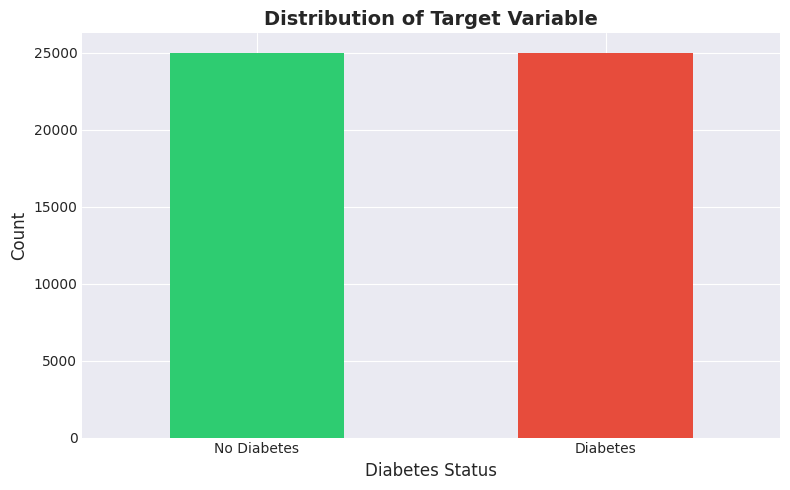

In [7]:
# Implementation 3: Analyze and visualize the target variable distribution
# HINT: For classification tasks, you need to understand class balance. How many samples 
#       are in each class (0 = no diabetes, 1 = diabetes)? Pandas Series (single columns) 
#       have methods to count the frequency of each unique value. You can also calculate 
#       percentages by normalizing these counts. Use matplotlib to visualize your key findings.
# REFERENCE: https://pandas.pydata.org/docs/reference/series.html
# Understanding class balance is critical for choosing appropriate metrics

target_distribution = df[TARGET].value_counts().sort_index()
target_percentage = df[TARGET].value_counts(normalize=True).sort_index() * 100

print("Target Variable Distribution:")
print(f"No Diabetes (0): {target_distribution[0]:,} ({target_percentage[0]:.2f}%)")
print(f"Diabetes (1): {target_distribution[1]:,} ({target_percentage[1]:.2f}%)")

# Visualize the distribution
fig, ax = plt.subplots(figsize=(8, 5))
target_distribution.plot(kind='bar', ax=ax, color=['#2ecc71', '#e74c3c'])
ax.set_xlabel('Diabetes Status', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.set_title('Distribution of Target Variable', fontsize=14, fontweight='bold')
ax.set_xticklabels(['No Diabetes', 'Diabetes'], rotation=0)
plt.tight_layout()
plt.show()

> **Understanding the balanced dataset:** You have noticed this dataset has a 50-50 split between diabetic and non-diabetic patients. The original CDC data actually has ~14% diabetes prevalence, reflecting real population statistics.
>
> Why did we balance it?
> - *Simplifies learning:* Lets you focus on neural network fundamentals without juggling class imbalance complexity
> - *Valid strategy:* Downsampling the majority class is common in production when you have enough minority samples (we have 7,000+ diabetic cases!)
> - *Practical benefits:* Simpler code, faster training, often performs just as well
>
> Alternatives to deal with class imbalance involve upsampling and/or cost-sensitive learning.
>
> *Production note:* You'd typically train on balanced data but evaluate on the real distribution. Here we use balanced for both to keep things simple, but remember to test on realistic proportions before deployment!

In [8]:
# Implementation 4: Examine basic statistical properties of the dataset
# HINT: Statistical summaries (mean, std, min, max, quartiles) help you understand feature 
#       distributions and identify potential outliers. DataFrames have built-in methods that 
#       compute these statistics across all numerical columns at once.
# REFERENCE: https://pandas.pydata.org/docs/reference/frame.html
# Pay attention to the ranges of different features since this informs normalization needs

display(df.describe().T)
print('Exact duplicate rows:', df.duplicated().sum())

,count,mean,std,min,25%,50%,75%,max
HighBP,50000.0,0.56118,0.496248,0.0,0.0,1.0,1.0,1.0
HighChol,50000.0,0.52728,0.499260,0.0,0.0,1.0,1.0,1.0
CholCheck,50000.0,0.97578,0.153733,0.0,1.0,1.0,1.0,1.0
BMI,50000.0,29.86934,7.183087,12.0,25.0,29.0,33.0,98.0
Smoker,50000.0,0.47422,0.499340,0.0,0.0,0.0,1.0,1.0
Stroke,50000.0,0.06210,0.241340,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,50000.0,0.15030,0.357369,0.0,0.0,0.0,0.0,1.0
PhysActivity,50000.0,0.70372,0.456621,0.0,0.0,1.0,1.0,1.0
Fruits,50000.0,0.61260,0.487161,0.0,0.0,1.0,1.0,1.0
Veggies,50000.0,0.78616,0.410019,0.0,1.0,1.0,1.0,1.0


Exact duplicate rows: 938


> **Understanding statistical summaries** Statistical summaries provide a quick snapshot of your dataset’s structure and variability.  
>
> - *Central tendency:* Metrics like mean and median reveal typical values but can be distorted by skewed data or outliers.  
> - *Spread:* Standard deviation and quartiles highlight how dispersed the data is, where wide spreads may indicate inconsistent scales or high variability.  
> - *Range and extremes:* Min/max values help spot potential data entry errors or outliers needing review.  
> - *Feature type awareness:*  
>   - Continuous features benefit from scale checks and normalization.  
>   - Ordinal or categorical features should be interpreted by the distribution of categories, not numeric statistics.  
>
> *Why this matters:* Understanding the shape, spread, and nature of your data guides preprocessing decisions like scaling, encoding, and handling outliers for reliable modeling.


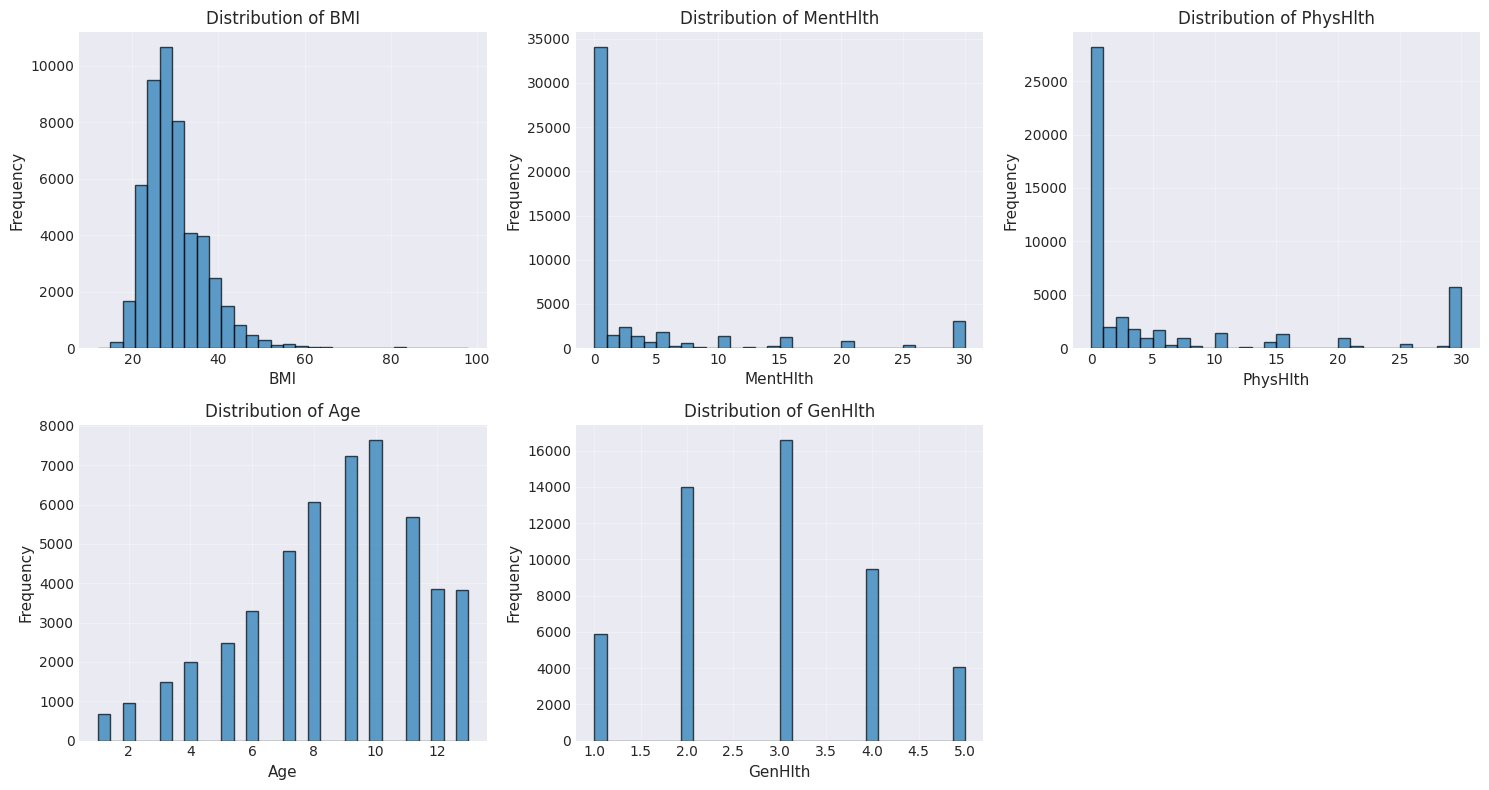

In [9]:
# Visualize distributions of key continuous features
continuous_features = ['BMI', 'MentHlth', 'PhysHlth', 'Age', 'GenHlth']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()

for idx, feature in enumerate(continuous_features):
    axes[idx].hist(df[feature], bins=30, edgecolor='black', alpha=0.7)
    axes[idx].set_xlabel(feature, fontsize=11)
    axes[idx].set_ylabel('Frequency', fontsize=11)
    axes[idx].set_title(f'Distribution of {feature}', fontsize=12)
    axes[idx].grid(True, alpha=0.3)

# Remove extra subplot
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

> **Interpreting the distribution plots** These histograms reveal how each continuous feature is distributed:  
> - *Shape:* Skewed or symmetric distributions indicate how values are spread.  
> - *Spread:* Wide distributions suggest high variability; scaling will be needed.  
> - *Peaks:* Multiple peaks can hint at subgroups or hidden patterns in the data.  
> - *Outliers:* Extreme values can distort model learning; worth investigating.  
> - *Continuity:* Features with few distinct values might behave more like categories.

Feature Correlations with Diabetes:
GenHlth                 0.406625
HighBP                  0.384610
HighChol                0.283302
BMI                     0.282141
Age                     0.280998
DiffWalk                0.270842
Income                 -0.226207
PhysHlth                0.215880
HeartDiseaseorAttack    0.208582
Education              -0.169717
PhysActivity           -0.160485
Stroke                  0.127208
CholCheck               0.113575
HvyAlcoholConsump      -0.099634
MentHlth                0.096566
Smoker                  0.085354
Veggies                -0.069071
Fruits                 -0.057641
Sex                     0.047573
NoDocbcCost             0.037306
AnyHealthcare           0.027282
Name: Diabetes_binary, dtype: float64


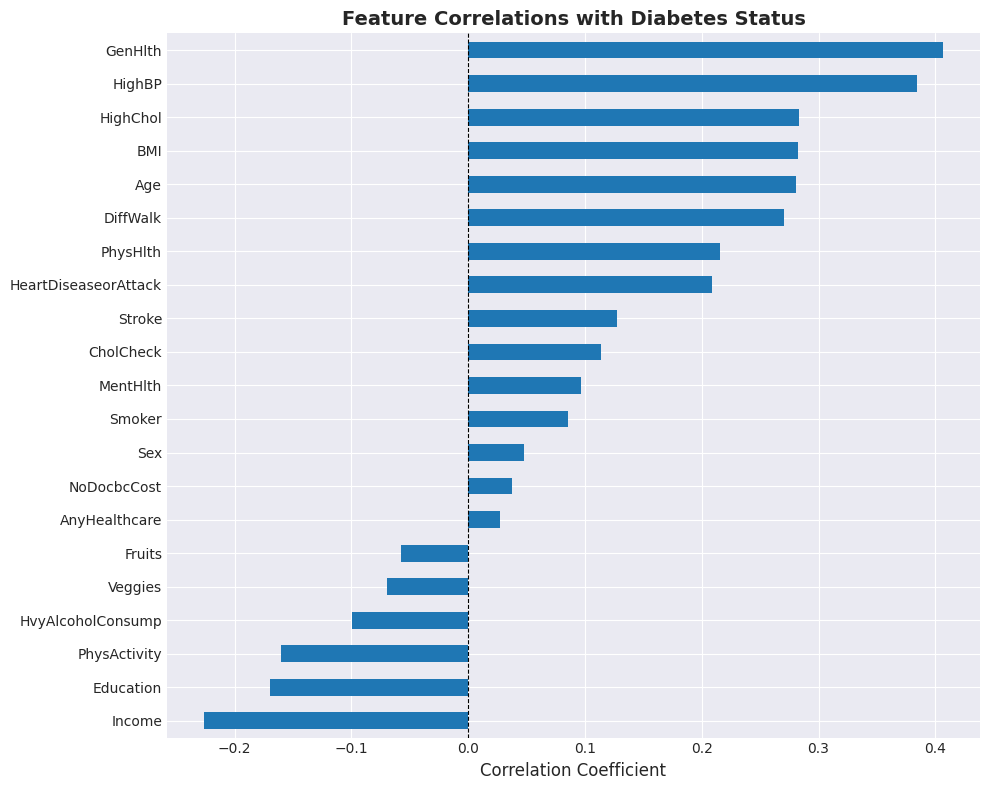

In [10]:
# Implementation 5: Analyze correlation between features and the target variable
# HINT: Correlation coefficients measure linear relationships between variables (-1 to +1).
#       You need to compute pairwise correlations between all features, then focus on 
#       correlations between each feature and your target variable. DataFrames can compute 
#       correlation matrices, and you can select specific columns from the result.
# REFERENCE: https://pandas.pydata.org/docs/reference/frame.html
# Strong correlations indicate features that may be predictive of diabetes

# Compute correlation with target
correlations = df.corr(numeric_only=True)[TARGET].drop(TARGET)
correlations = correlations.loc[correlations.abs().sort_values(ascending=False).index]

print("Feature Correlations with Diabetes:")
print(correlations)

# Visualize top correlations
fig, ax = plt.subplots(figsize=(10, 8))
correlations.sort_values().plot(kind='barh', ax=ax)
ax.set_xlabel('Correlation Coefficient', fontsize=12)
ax.set_title('Feature Correlations with Diabetes Status', fontsize=14, fontweight='bold')
ax.axvline(x=0, color='black', linestyle='--', linewidth=0.8)
plt.tight_layout()
plt.show()

> **Understanding correlations** Correlations show how features move together, not cause and effect.  
> - *Positive* → variables increase together; *Negative* → one rises as the other falls.  
> - Strong values (±1) imply tighter linear links; near 0 means weak or no linear relation.  
> - Watch for *multicollinearity* and remember that *nonlinear patterns* won’t appear here.  
>  
> *IMPORTANT*: Use correlations to spot patterns, not to draw conclusions.

### 1.4 Collect key observations from EDA

Document 5-10 key observations from the exploratory data analysis. Consider: class balance, feature ranges, correlations, missing data, and data quality.

**Observations from the supplied dataset**
- There are 50,000 records, 21 numeric predictors, and one binary target. The runtime tables above remain the source of truth if the CSV is replaced.
- The raw sample is exactly balanced: 25,000 records per class. The template's later reference to 86%/14% imbalance does not describe this file. Balanced-sample precision cannot be assumed to transfer to population screening.
- There are no missing values, but 938 exact duplicate rows. Remove these before stratified splitting to avoid placing identical complete records in different partitions; still check distinct records with identical predictor profiles.
- Many predictors are binary indicators. Age (1-13), Education (1-6), Income (1-8), and GenHlth (1-5) are ordered survey categories, not age in years or monetary income.
- BMI ranges from 12 to 98; mental/physical unhealthy days range from 0 to 30. Scaling learned only from training data avoids leakage and balances gradient magnitudes. Extreme BMI values deserve investigation rather than automatic removal.
- The strongest positive target correlations include GenHlth (0.407), HighBP (0.385), HighChol (0.283), BMI (0.282), and Age (0.281). Higher GenHlth means poorer reported health.
- Income has a negative correlation (-0.226), as do education and physical activity. These are associations, not causal effects or justification for discriminatory healthcare decisions.
- Correlations capture only pairwise linear association; the MLP can learn nonlinear relationships and interactions. No features are removed using full-dataset correlations.
- Survey data lack laboratory measurements and clinical diagnoses for deployment validation. Treat this as risk screening, not a diagnostic device.

<details open>
  <summary><h4>Checkpoint – Understanding the dataset</h4></summary>
  
  Before proceeding to preprocessing, ensure you understand:

  - [ ] The target variable distribution and its implications for evaluation
  - [ ] Which features show strong correlations with diabetes
  - [ ] The need for feature scaling due to different value ranges
  - [ ] The absence of missing values (simplifies preprocessing)

</details>

---
## Step 2: Preprocess the dataset

Proper data preprocessing is essential for neural network training. Raw data often needs to be split, normalized, and batched before it can be used effectively. This section transforms your dataset into a format optimized for PyTorch models.

### 2.1 Separate features and target

Machine learning models require splitting your data into input features (X) and target labels (y). The features are what the model uses to make predictions, while the target is what you're trying to predict. 

In [11]:
# Implementation 7: Separate features (X) and target variable (y)
# HINT: Identify the column representing the diabetes outcome, and store it separately.
#       The remaining columns will form your feature set.
#       DataFrames allow you to exclude columns or select specific ones using built-in methods.
# REFERENCE: https://pandas.pydata.org/docs/reference/frame.html
# Features are used for predicting the target variable.

modeling_df = df.drop_duplicates().reset_index(drop=True)
X = modeling_df.drop(columns=TARGET)
y = modeling_df[TARGET].astype(np.int64)

print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")
print(f"\nFeature columns: {list(X.columns)}")

Features shape: (49062, 21)
Target shape: (49062,)

Feature columns: ['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']


### 2.2 Create train/validation/test splits

Following best practices, you'll split the data into three sets:

- Training set (60%): Used to train the model (learn patterns, update weights)
- Validation set (20%): Used during development to tune hyperparameters and monitor overfitting
- Test set (20%): Final evaluation on completely unseen data (simulates real-world deployment)

This is a best practice because separating validation from testing ensures that model tuning doesn’t “leak” information from your final evaluation, leading to more trustworthy results.

In [12]:
# Implementation 8: Create train/validation/test splits with stratification
# HINT: scikit-learn provides utilities for splitting data while preserving class proportions.
#       You'll need to split in two stages: first separate training from temp, then split 
#       temp into validation and test. Each split should maintain the same diabetes/no-diabetes 
#       ratio as the original dataset. Look for a parameter that handles stratification.
# REFERENCE https://scikit-learn.org/stable/modules/classes.html#module-sklearn.model_selection
# While less critical with balanced data, stratification is still good practice and prevents any sampling bias.

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_SEED)
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)
assert len(X_train) + len(X_val) + len(X_test) == len(X)
print(f'Modeling rows after deduplication: {len(X):,}')

Modeling rows after deduplication: 49,062


In [13]:
# Verify split sizes and class distributions
print("Split Sizes:")
print(f"Training set: {X_train.shape[0]:,} samples ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"Validation set: {X_val.shape[0]:,} samples ({X_val.shape[0]/len(X)*100:.1f}%)")
print(f"Test set: {X_test.shape[0]:,} samples ({X_test.shape[0]/len(X)*100:.1f}%)")

print("\nClass Distribution:")
print(f"Training - Diabetes prevalence: {y_train.mean()*100:.2f}%")
print(f"Validation - Diabetes prevalence: {y_val.mean()*100:.2f}%")
print(f"Test - Diabetes prevalence: {y_test.mean()*100:.2f}%")

Split Sizes:
Training set: 34,343 samples (70.0%)
Validation set: 7,359 samples (15.0%)
Test set: 7,360 samples (15.0%)

Class Distribution:
Training - Diabetes prevalence: 50.70%
Validation - Diabetes prevalence: 50.70%
Test - Diabetes prevalence: 50.71%


<details open>
  <summary><h4>Checkpoint – Validate the data splits</h4></summary>
  
  Before continuing, make sure your dataset splits meet the expected proportions:

  - [ ] Training set contains approximately 60% of the data
  - [ ] Validation and test sets each contain approximately 20% of the data
  - [ ] Class presence is as expected (same ratio as for the full dataset) in all three splits

  If they aren’t, revisit your splitting logic before moving forward.

</details>

### 2.3 Normalize features

Neural networks perform better when input features are on similar scales. Standardization transforms features to have zero mean and unit variance, which helps gradients flow properly during training and speeds up convergence.

In [14]:
# Implementation 9: Normalize features with a training-only scaler
# HINT: Follow these general steps:
#         1. Create a scaling object from a preprocessing library
#         2. Fit it **only** on the training features to learn scaling parameters
#         3. Apply the same transformation to validation and test features
#       This maintains data consistency and prevents information leakage from validation or test sets.
# REFERENCE: https://scikit-learn.org/stable/modules/preprocessing.html#standardization-or-mean-removal-and-variance-scaling
# Normalization helps gradients converge more efficiently and prevents bias toward features with larger scales.

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train).astype(np.float32)
X_val_scaled = scaler.transform(X_val).astype(np.float32)
X_test_scaled = scaler.transform(X_test).astype(np.float32)
assert np.allclose(X_train_scaled.mean(axis=0), 0, atol=1e-5)
assert all(np.isfinite(values).all() for values in [X_train_scaled, X_val_scaled, X_test_scaled])

> **Don't forget the golden rule!** Only fit the scaler on training data to prevent data leakage, then use that fitted scaler to transform all three splits.   
> If you fit the scaler on validation or test data, their statistics (mean, standard deviation) would influence the training process. This is called *data leakage*, and leads to overly optimistic performance estimates. 
> <br><br>Think of it this way: In real deployment, you only have access to training data when building your model. The test set represents future, unseen entries that you should not have visibility on!

### 2.4 Convert to PyTorch tensors

PyTorch requires data to be in tensor format and batched for efficient GPU processing. DataLoaders handle batching, shuffling, and parallel data loading automatically.

In [15]:
# Implementation 10: Convert scaled NumPy arrays to PyTorch tensors
# HINT: Features should be floating-point tensors for 
#       neural network computations; this single-logit BCE model also needs float targets.
#       PyTorch provides tensor creation functions for different data types.
# REFERENCE: https://pytorch.org/docs/stable/torch.html#tensors
# Integer class-index targets would instead be appropriate for a two-logit CrossEntropyLoss model.

X_train_tensor = torch.from_numpy(X_train_scaled)
X_val_tensor = torch.from_numpy(X_val_scaled)
X_test_tensor = torch.from_numpy(X_test_scaled)
# BCEWithLogitsLoss requires float targets with the same (N, 1) shape as logits.
y_train_tensor = torch.from_numpy(y_train.to_numpy(dtype=np.float32)).reshape(-1, 1)
y_val_tensor = torch.from_numpy(y_val.to_numpy(dtype=np.float32)).reshape(-1, 1)
y_test_tensor = torch.from_numpy(y_test.to_numpy(dtype=np.float32)).reshape(-1, 1)

print("Conversion to PyTorch tensors completed!")
print(f"\nTraining features: {X_train_tensor.shape}, dtype: {X_train_tensor.dtype}")
print(f"Training labels: {y_train_tensor.shape}, dtype: {y_train_tensor.dtype}")

Conversion to PyTorch tensors completed!

Training features: torch.Size([34343, 21]), dtype: torch.float32
Training labels: torch.Size([34343, 1]), dtype: torch.float32


> **Why convert to tensors?** Neural networks run on *tensors*, not NumPy arrays, because tensors can live on the GPU and support automatic differentiation.  
> Converting ensures your data can be used efficiently during training and lets PyTorch handle gradients and fast parallel math.  
>  
> *IMPORTANT*: Avoid switching back and forth between NumPy and tensors: each conversion moves data between memory spaces and slows things down.  

In [16]:
# Implementation 11: Create DataLoaders for train, validation, and test sets
# HINT: PyTorch provides utilities in torch.utils.data to wrap tensors into datasets and create batching iterators.
#       You'll need to: (1) combine feature and label tensors into dataset objects, and 
#       (2) wrap datasets in loaders with appropriate batch sizes. Training data should be 
#       shuffled, but validation/test should not.
# REFERENCE: https://pytorch.org/tutorials/beginner/basics/data_tutorial.html
# Think about whether to apply difference DataLoader parameters for the three splits.

BATCH_SIZE = 512
EVAL_BATCH_SIZE = 2048
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
def make_train_loader():
    return DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                      generator=torch.Generator().manual_seed(RANDOM_SEED),
                      num_workers=0, pin_memory=device.type == 'cuda')
train_loader = make_train_loader()
val_loader = DataLoader(val_dataset, batch_size=EVAL_BATCH_SIZE, shuffle=False,
                        num_workers=0, pin_memory=device.type == 'cuda')
test_loader = DataLoader(test_dataset, batch_size=EVAL_BATCH_SIZE, shuffle=False,
                         num_workers=0, pin_memory=device.type == 'cuda')

print(f"Number of batches:")
print(f"Training: {len(train_loader)} batches")
print(f"Validation: {len(val_loader)} batches")
print(f"Test: {len(test_loader)} batches")

Number of batches:
Training: 68 batches
Validation: 4 batches
Test: 4 batches


In [17]:
# Verify DataLoader setup by examining one batch
for X_batch, y_batch in train_loader:
    print("Sample batch from training DataLoader:")
    print(f"Features shape: {X_batch.shape}")
    print(f"Labels shape: {y_batch.shape}")
    print(f"\nFeature sample (first 5 values): {X_batch[0, :5]}")
    print(f"Label sample (first 10): {y_batch[:10]}")
    break  # Only examine first batch

Sample batch from training DataLoader:
Features shape: torch.Size([512, 21])
Labels shape: torch.Size([512, 1])

Feature sample (first 5 values): tensor([ 0.8728, -1.0682,  0.1599, -0.1311,  1.0395])
Label sample (first 10): tensor([[1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [0.],
        [1.],
        [1.]])


> **Batch processing efficiency**: DataLoaders enable efficient mini-batch gradient descent by automatically batching your data. This allows for more stable gradient estimates than single-sample updates (SGD) while being more memory-efficient than using the entire dataset at once (batch gradient descent). Shuffling the training data each epoch prevents the model from learning the order of examples.

<details open>
  <summary><h4>Checkpoint – Validate the dataLoader output</h4></summary>
  
  Before training, confirm that your batches are correctly structured and preprocessed:
  
  - [ ] **Feature batch shape:** `(64, 21)` → 64 samples × 21 features  
  - [ ] **Label batch shape:** `(64,)` → 64 labels  
  - [ ] **Feature values:** normalized 
  - [ ] **Labels:** binary values (**0 or 1**)  
  
  If any shapes or values look off, revisit your preprocessing or batching steps before proceeding.
</details>

---
## Step 3: Design the model architecture

Now it's time to design your neural network! You'll build a multi-layer perceptron (MLP): a feed-forward neural network that learns from health indicators to predict diabetes risk. The goal is to define an architecture that balances **expressiveness** (ability to learn complex patterns) and **efficiency** (training speed and generalization).


### 3.1 Design considerations

Before implementing the model, consider these architectural decisions:

**Input Layer**:
- Size: Must match the number of features in the dataset (21 for our diabetes data)

**Hidden Layers**:
- **Depth**: Deeper networks can capture more complex patterns but increase the risk of overfitting and slow down training
- **Width**: Choose enough neurons to represent useful feature interactions without overcomplicating the model  
- **Activation**: Non-linear activations (like ReLU) allow the model to learn complex relationships beyond simple linear boundaries  

**Output Layer**:
- Size: Single neuron for binary classification (outputs probability of diabetes)
- Output: one raw logit per record, shape `(batch_size, 1)`. `BCEWithLogitsLoss` combines sigmoid and binary cross-entropy stably during training; apply sigmoid only for probability reporting and thresholding.

### 3.2 Implement the neural network

You'll create a Multi-Layer Perceptron (MLP) using PyTorch's `nn.Module` class. This approach lets you define each layer and the forward pass explicitly, giving you full control over your model’s behavior.

In [18]:
# Implementation 12: Define the DiabetesClassifier neural network class
# HINT: In PyTorch, models are defined as classes that inherit from nn.Module.
#       Within the constructor, specify your linear layers and activations.
#       Then implement the forward() method to describe how data flows through them.
#       Remember: Add non-linear activations between layers to help the network learn complex patterns;
#       also think about the loss function you'll use as it will inform your model output.
# REFERENCE: https://docs.pytorch.org/docs/stable/generated/torch.nn.Module.html
# Define your architecture thoughtfully based on design considerations.

class DiabetesClassifier(nn.Module):

    def __init__(self, input_dim: int = 21,
                 hidden_sizes: Tuple[int, ...] = (64, 32), dropout: float = 0.0):
        super().__init__()
        if input_dim < 1 or len(hidden_sizes) < 2 or any(size < 1 for size in hidden_sizes):
            raise ValueError('Use a positive input dimension and at least two positive hidden sizes.')
        if not 0 <= dropout < 1:
            raise ValueError('Dropout must be in [0, 1).')
        layers = []
        previous_size = input_dim
        for size in hidden_sizes:
            layers.extend([nn.Linear(previous_size, size), nn.ReLU()])
            if dropout:
                layers.append(nn.Dropout(dropout))
            previous_size = size
        layers.append(nn.Linear(previous_size, 1))
        self.network = nn.Sequential(*layers)

    def forward(self, inputs: torch.Tensor) -> torch.Tensor:
        return self.network(inputs)

### 3.3 Instantiate and inspect the model

Once the architecture is defined, create an instance of your model and inspect its structure. Understanding your model's parameters and layers helps ensure it's built as intended and gives you insight into its complexity.

In [19]:
# Implementation 13: Create a model instance on the selected device
# HINT: Initialize your class just like any Python object. You can use the default
#       hidden layer sizes or adjust them for experimentation.
#       After instantiation, set the model on the device. Then, printing the model will display its structure.
# REFERENCE: https://discuss.pytorch.org/t/how-to-print-a-model-after-load-it/9879/7

torch.manual_seed(RANDOM_SEED)
model = DiabetesClassifier(input_dim=X_train_tensor.shape[1]).to(device)

print("Model Architecture:")
print(model)
print("\n" + "="*50)

Model Architecture:
DiabetesClassifier(
  (network): Sequential(
    (0): Linear(in_features=21, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)



In [20]:
# Count total parameters in the model
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

# Display parameter breakdown by layer
print("\nParameter breakdown:")
for name, param in model.named_parameters():
    print(f"{name:20s} - Shape: {str(param.shape):20s} - Parameters: {param.numel():,}")

Total parameters: 3,521
Trainable parameters: 3,521

Parameter breakdown:
network.0.weight     - Shape: torch.Size([64, 21]) - Parameters: 1,344
network.0.bias       - Shape: torch.Size([64])     - Parameters: 64
network.2.weight     - Shape: torch.Size([32, 64]) - Parameters: 2,048
network.2.bias       - Shape: torch.Size([32])     - Parameters: 32
network.4.weight     - Shape: torch.Size([1, 32])  - Parameters: 32
network.4.bias       - Shape: torch.Size([1])      - Parameters: 1


> **Understanding model inspection** Inspecting your model helps confirm that the architecture matches your design intent, both in structure and in parameter count.  
>  
> - *Check layer flow:* Verify inputs and outputs connect as expected, especially when stacking layers or combining modules.  
> - *Parameter awareness:* Knowing where parameters concentrate helps spot over- or under-parameterized designs early.  
> - *Debugging aid:* If training behaves unexpectedly, inspection can reveal mismatched layer sizes, missing activations, or frozen parameters.  
> - *Efficiency check:* Smaller models train faster but may underfit; larger ones capture complexity but risk overfitting.  
>  
> Regular inspection builds intuition about how architectural choices impact learning and performance.


### 3.4 Test the forward pass

Before training, confirm that your model processes input data correctly. This step ensures that tensor shapes are compatible and that the output has the expected dimensions for binary classification.

In [21]:
# Implementation 14: Test the forward pass with a sample batch
# HINT: Retrieve one batch from your DataLoader and pass it through the model, after moving it to device.
#       Check that the output tensor’s shape matches expectations (one probability per sample).
#       This step validates that your forward() method and layer dimensions are correct.
# REFERENCE: Review "forward propagation in PyTorch" and "DataLoader iteration examples".
# Expected output shape: (batch_size, 1)

# Get a sample batch
for X_batch, y_batch in train_loader:
    # Move data to device
    X_batch = X_batch.to(device)

    # Forward pass
    model.eval()
    with torch.inference_mode():
        output = model(X_batch)
    assert output.shape == (X_batch.shape[0], 1)
    assert y_batch.shape == output.shape
    assert X_batch.dtype == y_batch.dtype == torch.float32
    assert torch.isfinite(output).all()
    
    print("Forward Pass Test:")
    print(f"Input shape: {X_batch.shape}")
    print(f"Output shape: {output.shape}")
    print(f"\nSample output (first 10):")
    print(torch.sigmoid(output[:10]).squeeze().cpu().numpy())
    print(f"\nActual labels (first 10):")
    print(y_batch[:10].numpy())
    
    break  # Only test with first batch

Forward Pass Test:
Input shape: torch.Size([512, 21])
Output shape: torch.Size([512, 1])

Sample output (first 10):
[0.44044483 0.47555453 0.45931438 0.45816115 0.45219392 0.45286092
 0.4942161  0.479818   0.4652509  0.46597487]

Actual labels (first 10):
[[1.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [1.]
 [1.]
 [1.]
 [0.]]


> **Interpreting the forward pass test** If the model runs without errors and outputs a tensor with the expected shape, your architecture and data pipeline are aligned.  
> Unexpected shapes, NaNs, or all-identical predictions can signal setup issues worth fixing before training.  
>  
> Passing this check means you’re ready to move on to loss computation and optimization.


<details open>
  <summary><h4>Checkpoint – Verify Model Architecture</h4></summary>
  
  Before training, ensure your model is correctly defined:
  
  - [ ] **Model instantiated** without errors  
  - [ ] **Architecture matches expectations**: Input size = # features, hidden layers = right complexity for task, output = supports binary classification  
  - [ ] **Model moved to correct device** (GPU if available)  
  
  If anything looks incorrect, revisit your model definition before proceeding to training.
</details>

---
## Step 4: Train the model

Training a neural network involves repeatedly cycling through the data, computing predictions, calculating loss, and updating weights through backpropagation. This section implements the complete training loop with proper validation monitoring.

### 4.1  Define loss function and optimizer

The loss function measures how wrong your model's predictions are, while the optimizer determines how to update weights to reduce this error.

For binary classification with probabilistic outputs (values between 0 and 1), which loss function is most appropriate? Which optimizer is commonly recommended as a strong default for neural networks?

In [22]:
# Implementation 15: Define loss function and optimizer
# HINT: Choose a binary classification loss that measures the difference 
#       between predicted probabilities and true labels.
#       Then, initialize an optimizer that updates model weights efficiently.
#       Remember to pass model parameters to the optimizer and select a reasonable learning rate.
# REFERENCE: https://docs.pytorch.org/docs/stable/nn.html#loss-functions, https://docs.pytorch.org/docs/stable/optim.html
# Tip: Adaptive optimizers adjust learning rates automatically, which makes them reliable defaults.

criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("Training configuration:")
print(f"Loss function: {criterion}")
print(f"Optimizer: {optimizer.__class__.__name__}")
print(f"Learning rate: {optimizer.param_groups[0]['lr']}")
print(f"Number of parameter groups: {len(optimizer.param_groups)}")

Training configuration:
Loss function: BCEWithLogitsLoss()
Optimizer: Adam
Learning rate: 0.001
Number of parameter groups: 1


> **Defining the training setup for binary classification:** For binary classification, you need a loss that compares predicted probabilities against binary targets.  
> When choosing an optimizer, consider:  
> - How *stable* you want learning to be (adaptive methods help when tuning is tricky).  
> - How much *control* you need over learning rates or momentum.  
>  
> The “best” choice often depends on your data size, feature scale, and how smoothly the model learns; experiment and observe training behavior.


### 4.2 Implement the training loop

The training loop orchestrates the entire learning process: forward pass, loss computation, backward pass, and weight updates. Validation during training helps detect overfitting early.

In [23]:
# Implementation 16: Complete training loop with validation monitoring
# HINT: A complete training loop has two phases per epoch:
#       
#       TRAINING PHASE: For each epoch:
#       - Iterate through training batches
#       - Move batches to device
#       - For each batch: clear old gradients → forward pass → compute loss → 
#         backward pass → update weights
#       - Track average training loss and other relevant performance metrics
#       
#       VALIDATION PHASE:
#       - Set model to evaluation mode (disables dropout, batchnorm updates)
#       - Iterate through validation batches WITHOUT computing gradients
#       - Calculate average validation loss and other relevant performance metrics
#       
#       The PyTorch training pattern involves specific method calls on the model, optimizer, 
#       and loss. 
#
#       LOGGING:
#       - Use the `print_every` argument to conditionally print progress (epoch index, avg train/val loss).
#
# REFERENCE: https://pytorch.org/tutorials/beginner/basics/optimization_tutorial.html

def train_model(model: nn.Module,
                train_loader: DataLoader,
                val_loader: DataLoader,
                criterion: nn.Module,
                optimizer: optim.Optimizer,
                device: torch.device,
                num_epochs: int = 25,
                print_every: int = 5,
                patience: Optional[int] = None) -> Tuple[int, List[float], List[float]]:
    """
    Train a PyTorch model with validation monitoring.
    
    Args:
        model: PyTorch model to train
        train_loader: DataLoader for training data
        val_loader: DataLoader for validation data
        criterion: Loss function
        optimizer: Optimizer
        device: Device to train on (CPU or GPU)
        num_epochs: Number of training epochs
        print_every: Print progress every N epochs
        patience: Optional early-stopping patience; restores the lowest-validation-loss weights.
    
    Returns:
        Tuple of (completed_epochs, train_losses, val_losses), with one loss per completed epoch.
    """

    # Lists to track metrics over epochs
    train_losses = []
    val_losses = []
    
    if num_epochs < 1 or print_every < 1 or (patience is not None and patience < 1):
        raise ValueError('Epoch count, print interval, and optional patience must be positive.')
    if len(train_loader.dataset) == 0 or len(val_loader.dataset) == 0:
        raise ValueError('Training and validation datasets must not be empty.')
    best_loss = float('inf')
    best_state = None
    stale_epochs = 0
    started = perf_counter()
    for epoch in range(num_epochs):
        model.train()
        train_total = torch.zeros((), device=device)
        train_count = 0
        for inputs, targets in train_loader:
            inputs = inputs.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(inputs), targets)
            loss.backward()
            optimizer.step()
            train_total += loss.detach() * len(inputs)
            train_count += len(inputs)
        model.eval()
        val_total = torch.zeros((), device=device)
        val_count = 0
        with torch.inference_mode():
            for inputs, targets in val_loader:
                inputs = inputs.to(device, non_blocking=True)
                targets = targets.to(device, non_blocking=True)
                val_total += criterion(model(inputs), targets) * len(inputs)
                val_count += len(inputs)
        train_loss = (train_total / train_count).item()
        val_loss = (val_total / val_count).item()
        if not np.isfinite([train_loss, val_loss]).all():
            raise FloatingPointError(f'Nonfinite loss at epoch {epoch + 1}.')
        train_losses.append(train_loss)
        val_losses.append(val_loss)
        if val_loss < best_loss:
            best_loss = val_loss
            model.best_epoch = epoch + 1
            if patience is not None:
                best_state = copy.deepcopy(model.state_dict())
            stale_epochs = 0
        else:
            stale_epochs += 1
        if epoch == 0 or (epoch + 1) % print_every == 0:
            print(f'Epoch {epoch + 1:02d}: train={train_loss:.4f}, validation={val_loss:.4f}')
        if patience is not None and stale_epochs >= patience:
            print(f'Early stopping at epoch {epoch + 1}; restoring epoch {model.best_epoch}.')
            break
    if best_state is not None:
        model.load_state_dict(best_state)
    model.training_seconds = perf_counter() - started
    model.eval()

    print("\nTraining completed!")
    print(f"Final Train Loss: {train_losses[-1]:.4f}")
    print(f"Final Validation Loss: {val_losses[-1]:.4f}")

    return len(train_losses), train_losses, val_losses

num_epochs, train_losses, val_losses = train_model(
    model=model,
    train_loader=make_train_loader(),
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    device=device
)

Epoch 01: train=0.5836, validation=0.5214
Epoch 05: train=0.5083, validation=0.5114
Epoch 10: train=0.5030, validation=0.5101
Epoch 15: train=0.5005, validation=0.5106
Epoch 20: train=0.4980, validation=0.5108
Epoch 25: train=0.4962, validation=0.5118

Training completed!
Final Train Loss: 0.4962
Final Validation Loss: 0.5118


> **Beware of gradient accumulation!** By default, PyTorch accumulates gradients across batches. Without resetting them, gradients from previous iterations are added to those from the current batch, which can lead to incorrect weight updates. A reset step is needed before each backward pass to prevent this.

### 4.3 Visualize training progress

Loss curves are your primary debugging tool for neural networks. They reveal whether your model is learning properly, overfitting, or underfitting.

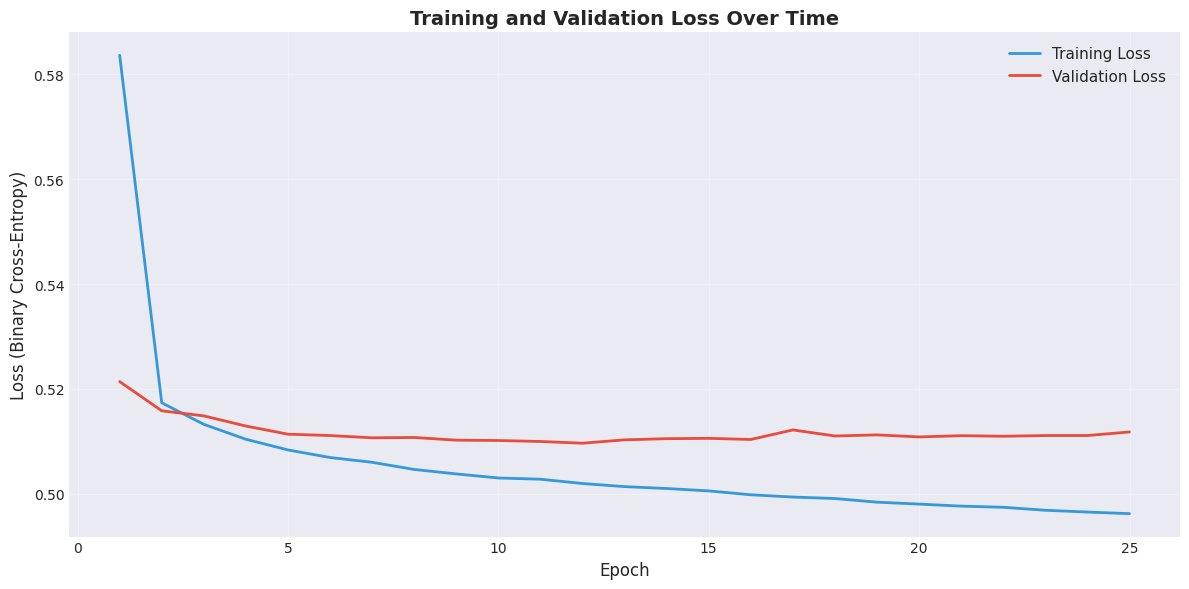


Loss Statistics:
Initial Train Loss: 0.5836
Final Train Loss: 0.4962
Initial Val Loss: 0.5214
Final Val Loss: 0.5118

Loss Reduction:
Training: 15.0% decrease
Validation: 1.8% decrease


**Baseline loss-curve interpretation (measured):** Overall healthy learning: both losses improve; inspect any late plateau in the plot. Training loss changes from 0.5836 to 0.4962; validation changes from 0.5214 to 0.5118, with its minimum 0.5096 at epoch 12. The final validation-minus-training gap is 0.0156. The network has learned transferable signal, although a remaining gap indicates imperfect generalization.

In [24]:
# Plot training and validation loss curves

plt.figure(figsize=(12, 6))

epochs_range = range(1, num_epochs + 1)
plt.plot(epochs_range, train_losses, label='Training Loss', linewidth=2, color='#3498db')
plt.plot(epochs_range, val_losses, label='Validation Loss', linewidth=2, color='#e74c3c')

plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Loss (Binary Cross-Entropy)', fontsize=12)
plt.title('Training and Validation Loss Over Time', fontsize=14, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Print final statistics
print(f"\nLoss Statistics:")
print(f"Initial Train Loss: {train_losses[0]:.4f}")
print(f"Final Train Loss: {train_losses[-1]:.4f}")
print(f"Initial Val Loss: {val_losses[0]:.4f}")
print(f"Final Val Loss: {val_losses[-1]:.4f}")
print(f"\nLoss Reduction:")
print(f"Training: {((train_losses[0] - train_losses[-1]) / train_losses[0] * 100):.1f}% decrease")
print(f"Validation: {((val_losses[0] - val_losses[-1]) / val_losses[0] * 100):.1f}% decrease")

def describe_losses(training, validation):
    gap = validation[-1] - training[-1]
    best_epoch = int(np.argmin(validation)) + 1
    if training[-1] < training[0] and validation[-1] > min(validation) + 0.01:
        diagnosis = 'Overfitting: training loss falls, but validation loss rebounds from its minimum.'
        implication = 'The later updates fit training-specific patterns instead of improving generalization.'
    elif training[-1] > 0.65 and validation[-1] > 0.65:
        diagnosis = 'Possible underfitting: both losses remain near the uninformative binary-loss level.'
        implication = 'Inspect convergence and capacity before assuming the predictors contain no signal.'
    elif validation[-1] < validation[0]:
        diagnosis = 'Overall healthy learning: both losses improve; inspect any late plateau in the plot.'
        implication = 'The network has learned transferable signal, although a remaining gap indicates imperfect generalization.'
    else:
        diagnosis = 'Unstable or ineffective validation learning: the final validation loss does not improve.'
        implication = 'Reconsider optimization and regularization; training improvement alone is insufficient.'
    return (f'{diagnosis} Training loss changes from {training[0]:.4f} to {training[-1]:.4f}; '
            f'validation changes from {validation[0]:.4f} to {validation[-1]:.4f}, '
            f'with its minimum {min(validation):.4f} at epoch {best_epoch}. '
            f'The final validation-minus-training gap is {gap:.4f}. {implication}')
display(Markdown('**Baseline loss-curve interpretation (measured):** ' + describe_losses(train_losses, val_losses)))

### 4.4 Interpret the loss curves

Understanding loss curves is critical for diagnosing model performance. Here are the patterns to look for:

 Pattern | Loss Behavior | Interpretation | Possible Fixes |
|----------|----------------|----------------|----------------|
| **Healthy Training** | • Both training & validation loss decrease and converge<br>• Small gap between them | Model is learning generalizable patterns | — |
| **Overfitting** | • Training loss keeps decreasing<br>• Validation loss plateaus or increases<br>• Large gap between curves | Model memorizes training data instead of generalizing | Add regularization (dropout, weight decay)<br>Reduce model complexity<br>Collect more data |
| **Underfitting** | • Both losses remain high<br>• Little or no improvement over epochs | Model lacks capacity or training | Increase model complexity<br>Train longer<br>Tune learning rate<br>Improve input features |

Diagnose your model's performance based on loss curves. Answer these questions by analyzing the plot above, either through code or markdown:
 1. What pattern do you see? Does the plot show healthy training, overfitting, or underfitting?
 2. How do you know? _Describe the behavior of the training loss line vs. the validation loss line. (e.g., "Training loss is [decreasing/high] while validation loss is [decreasing/increasing/high]")._
 3. What does this imply? What is the model doing wrong (or right)? _(e.g., "The model is memorizing the training data but failing to generalize...")_

**Answer:** The result-specific written diagnosis is generated immediately below the baseline loss plot. It reports the observed direction of both curves, their minimum validation epoch and final gap, and explains whether the pattern suggests generalization, overfitting, or possible underfitting. The thresholds used to flag patterns are descriptive heuristics, not clinical acceptance criteria.

<details open>
  <summary><h4>Checkpoint – Assess Training Progressing</h4></summary>
  
  Before moving to evaluation, verify that training completed successfully:
  
  - [ ] **Training completed** without errors across all epochs  
  - [ ] **Loss curves analyzed** and any overfitting or underfitting noted  
  - [ ] **Model ready** for comprehensive evaluation on test set  
  
  If training seems problematic (e.g., losses not decreasing), don't worry about it now - that's what optimizations in step 6 will focus on improving!
</details>

---
## Step 5: Evaluate the model

Training loss tells you how well the model fits training data, but comprehensive evaluation requires measuring performance on unseen test data using metrics relevant to your application. 

For medical screening, certain metrics matter more than others. For the baseline model, just check that performance is good-enough (significantly better than random guessing).

### 5.1 Define the evaluation logic

We'll create now a parameterized function that evaluates any model and returns comprehensive metrics.

In [25]:
# Implementation 18: Evaluate a trained model on new data
# HINT: This function should test how well your model performs by:
#       1. Setting the model to evaluation mode (to disable dropout, etc.)
#       2. Looping through the evaluation DataLoader without tracking gradients
#       3. Collecting predictions and true labels for each batch
#       4. Converting these results to NumPy arrays for metric calculations
#       5. Computing relevant performance metrics for the use case
#       6. Returning all computed values in a single dictionary for easy analysis
#       This function helps summarize how well your trained model generalizes to unseen data.
# REFERENCE: https://scikit-learn.org/stable/modules/model_evaluation.html
# The model outputs logits; sigmoid converts them to probabilities for evaluation.

def classification_results(probabilities, labels, threshold=0.5):
    if not 0 <= threshold <= 1:
        raise ValueError('Threshold must be in [0, 1].')
    probabilities = np.asarray(probabilities).reshape(-1)
    labels = np.asarray(labels).reshape(-1)
    if len(labels) == 0 or len(labels) != len(probabilities):
        raise ValueError('Evaluation needs nonempty, aligned labels and probabilities.')
    if not np.isfinite(probabilities).all() or np.any((probabilities < 0) | (probabilities > 1)):
        raise ValueError('Predicted probabilities must be finite and in [0, 1].')
    if set(np.unique(labels)) != {0, 1}:
        raise ValueError('Evaluation and ROC AUC require both binary classes.')
    labels = labels.astype(np.int64)
    predicted = (probabilities >= threshold).astype(np.int64)
    tn, fp, fn, tp = metrics.confusion_matrix(labels, predicted, labels=[0, 1]).ravel()
    return {
        'accuracy': metrics.accuracy_score(labels, predicted),
        'precision': metrics.precision_score(labels, predicted, zero_division=0),
        'recall': metrics.recall_score(labels, predicted, zero_division=0),
        'f1': metrics.f1_score(labels, predicted, zero_division=0),
        'specificity': float(tn / (tn + fp)),
        'roc_auc': metrics.roc_auc_score(labels, probabilities),
        'pr_auc': metrics.average_precision_score(labels, probabilities),
        'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),
        'threshold': float(threshold), 'predictions': probabilities,
        'true_labels': labels, 'pred_labels': predicted,
    }

def evaluate_model(model: nn.Module, 
                   data_loader: DataLoader, 
                   device: torch.device,
                   threshold: float = 0.5) -> Dict[str, object]:
    """
    Evaluate a trained model on a dataset and return comprehensive metrics.
    
    Args:
        model: Trained PyTorch model
        data_loader: DataLoader containing the evaluation dataset
        device: Device to run evaluation on (CPU or GPU)
        threshold: Decision threshold for classification (default: 0.5)
    
    Returns:
        Dictionary containing:
            - predictions: numpy array of predicted probabilities
            - true_labels: numpy array of true labels
            - pred_labels: numpy array of predicted binary labels
            - metrics
    """
    all_predictions = []
    all_labels = []
    model.eval()
    with torch.inference_mode():
        for inputs, labels in data_loader:
            logits = model(inputs.to(device, non_blocking=True))
            all_predictions.append(torch.sigmoid(logits).cpu())
            all_labels.append(labels.cpu())
    if not all_labels:
        raise ValueError('Evaluation DataLoader is empty.')
    return classification_results(torch.cat(all_predictions).numpy(),
                                  torch.cat(all_labels).numpy(), threshold)

print("Evaluation function created successfully!")

Evaluation function created successfully!


> **Why accuracy isn't enough (even with balanced data):** While accuracy is now meaningful with our 50-50 split (unlike with imbalanced data where it'd be misleading), it still doesn't tell the whole story in medical applications.
> 
> Consider: A model with 75% accuracy could have 90% recall but only 60% precision—great at catching diabetic patients but with many false alarms. Or it could have 90% precision but 60% recall—very accurate when it predicts diabetes, but missing many cases.
> 
> *Bottom line:* Choose metrics that provide a clear view over this trade-off; this is critical in healthcare where different errors have different costs!

### 5.2 Evaluate on test set

Now we'll use our evaluation function to assess the baseline model's performance on the held-out test set. This gives us an unbiased estimate of real-world performance.

In [26]:
# Implementation 19: Evaluate the baseline on the test set
# HINT: Call evaluate_model() with your trained model and test_loader.
#       Extract the metrics from the returned dictionary and display them.

baseline_val_results = evaluate_model(model, val_loader, device)
test_results = evaluate_model(model, test_loader, device)
display(pd.DataFrame([{k: value for k, value in test_results.items()
                       if isinstance(value, numbers.Number)}], index=['Baseline test']).round(4))
print('The baseline test scores are reported, but are not used for configuration selection.')


,accuracy,precision,recall,f1,specificity,roc_auc,pr_auc,tn,fp,fn,tp,threshold
Baseline test,0.7443,0.7301,0.7864,0.7572,0.7009,0.8207,0.7995,2543,1085,797,2935,0.5


The baseline test scores are reported, but are not used for configuration selection.


> **Choosing the top metric:** Which is worse for your stakeholders: missing a diabetic patient or triggering an unnecessary test? This determines whether you prioritize recall or precision, and informs threshold selection (we'll use 0.5 as default, but you could adjust it).

### 5.3 Visualize the confusion matrix

The confusion matrix shows exactly where your model succeeds and fails, breaking down predictions into true positives, true negatives, false positives, and false negatives.

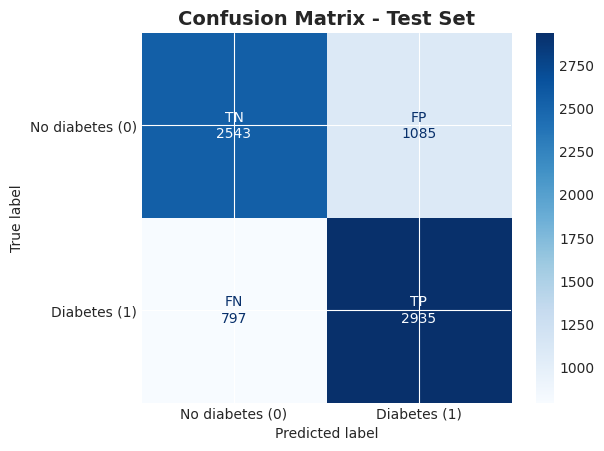

In [27]:
# Implementation 20: Create and visualize the confusion matrix
# HINT: Use sklearn to calculate and visualize the confusion matrix.
#       This approach automatically labels axes (true vs. predicted) and provides a clean layout.
#       Optionally, you can adjust color maps or figure size for better readability.
# REFERENCE: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.ConfusionMatrixDisplay.html

disp = metrics.ConfusionMatrixDisplay.from_predictions(
    test_results['true_labels'], test_results['pred_labels'], labels=[0, 1],
    display_labels=['No diabetes (0)', 'Diabetes (1)'], cmap='Blues', colorbar=True)
for row, column, label in [(0, 0, 'TN'), (0, 1, 'FP'), (1, 0, 'FN'), (1, 1, 'TP')]:
    disp.text_[row, column].set_text(f'{label}\n{disp.confusion_matrix[row, column]}')
plt.title('Confusion Matrix - Test Set', fontsize=14, fontweight='bold')
plt.show()

> **Interpreting your confusion matrix** The confusion matrix makes the trade-offs between recall and precision visible. By examining the balance between false positives and false negatives, you can decide which matters more for your real-world goal; for example, catching every diabetic case even if it means more false alarms.

### 5.4 Analyze ROC curve and threshold selection

The ROC (Receiver Operating Characteristic) curve helps you visualize the tradeoff between sensitivity (catching true cases) and specificity (avoiding false alarms) at different decision thresholds.

*Why this matters:*
- The default threshold is 0.5 (predict diabetes if probability > 0.5)
- You might want a different threshold based on your priorities:
  - Lower threshold (e.g., 0.3) → Higher recall, catch more diabetics, but more false alarms
  - Higher threshold (e.g., 0.7) → Higher precision, fewer false alarms, but miss more cases


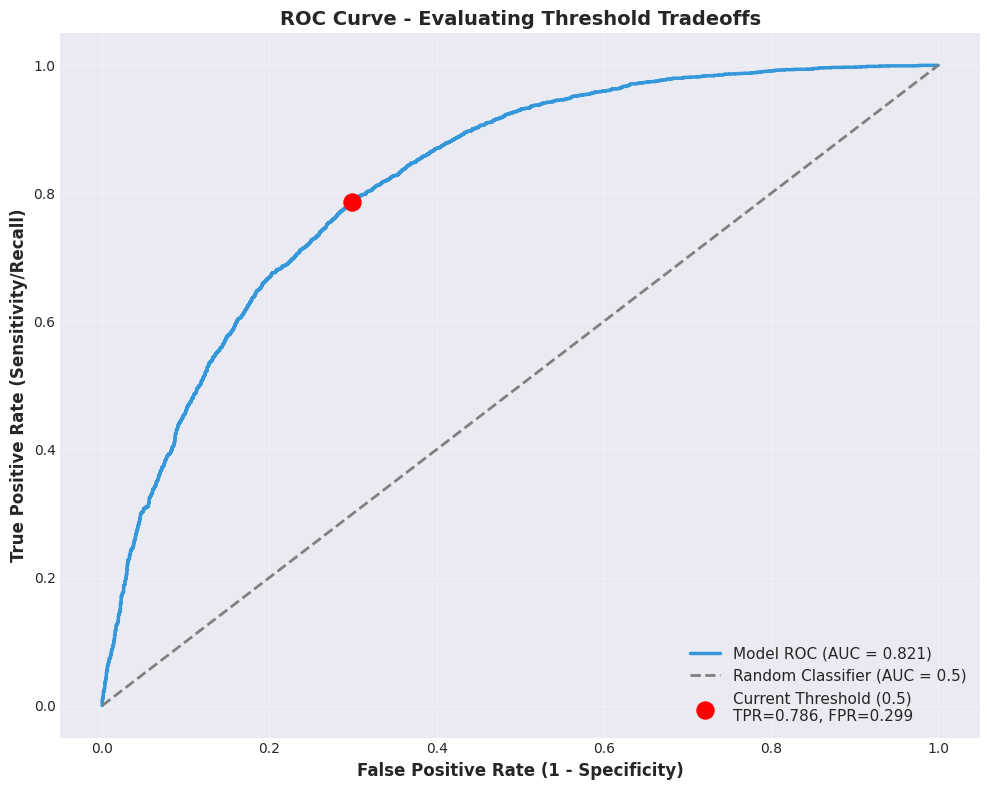


ROC Curve Analysis:
AUC Score: 0.8207
Interpretation:
  - Good discrimination ability


**Baseline healthcare results (test, threshold 0.5):** recall 0.7864, precision 0.7301, F1 0.7572, accuracy 0.7443, ROC AUC 0.8207. There are **797 false negatives** and **1085 false positives**. Missing positive cases motivates validation-only sensitivity/threshold tuning, but the baseline is not ready for autonomous clinical deployment.

In [28]:
# Implementation 21: Generate and plot the ROC curve
# HINT: The ROC curve shows how your model’s ability to distinguish between classes 
#       changes as you vary the classification threshold: the closer the curve hugs the top-left corner, 
#       the better the model separates positives and negatives. Then, the Area Under the Curve (AUC) quantifies 
#       this performance: higher AUC also means better separability. This as a rule-of-thumb:
#            * 0.90–1.00 → Excellent discrimination
#            * 0.80–0.89 → Good discrimination
#            * 0.70–0.79 → Fair discrimination
#            * Below 0.70 → Poor discrimination
#       Use this plot and AUC value to reason about which threshold best aligns with your real-world trade-offs.
# REFERENCE: https://developers.google.com/machine-learning/crash-course/classification/roc-and-auc

# Calculate ROC curve
fpr, tpr, thresholds = metrics.roc_curve(test_results['true_labels'], test_results['predictions'])
roc_auc = test_results['roc_auc']

# Plot ROC curve
plt.figure(figsize=(10, 8))
plt.plot(fpr, tpr, color='#3498db', linewidth=2.5, label=f'Model ROC (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', linewidth=2, label='Random Classifier (AUC = 0.5)')

# Mark the current operating point (threshold = 0.5)
current_tpr = test_results['recall']
current_fpr = 1 - test_results['specificity']
plt.scatter(current_fpr, current_tpr, color='red', s=150, zorder=5,
            label=f'Current Threshold (0.5)\nTPR={current_tpr:.3f}, FPR={current_fpr:.3f}')

plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12, fontweight='bold')
plt.ylabel('True Positive Rate (Sensitivity/Recall)', fontsize=12, fontweight='bold')
plt.title('ROC Curve - Evaluating Threshold Tradeoffs', fontsize=14, fontweight='bold')
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\nROC Curve Analysis:")
print("="*60)
print(f"AUC Score: {roc_auc:.4f}")
print(f"Interpretation:")
if roc_auc >= 0.90:
    print("  - Excellent discrimination ability")
elif roc_auc >= 0.80:
    print("  - Good discrimination ability")
elif roc_auc >= 0.70:
    print("  - Fair discrimination ability")
else:
    print("  - Poor discrimination ability")

display(Markdown(
    f'**Baseline healthcare results (test, threshold 0.5):** recall '
    f'{test_results["recall"]:.4f}, precision {test_results["precision"]:.4f}, '
    f'F1 {test_results["f1"]:.4f}, accuracy {test_results["accuracy"]:.4f}, '
    f'ROC AUC {test_results["roc_auc"]:.4f}. There are **{test_results["fn"]} '
    f'false negatives** and **{test_results["fp"]} false positives**. '
    'Missing positive cases motivates validation-only sensitivity/threshold tuning, '
    'but the baseline is not ready for autonomous clinical deployment.'
))

> **Understanding the ROC curve**: Each point on the ROC curve represents a different probability threshold for classification. Points in the upper-left corner represent high sensitivity (catching most cases) with low false positive rates (few false alarms). The diagonal line represents random guessing. Depending on your prioritization, you might adjust the threshold as follows:
> - If missing positives is costly, lower the threshold to get the model to label more cases as "positive" → higher true positive rate, higher false positive rate.
> - If false alarms are costly, raise the threshold to get the model to be more strict in labeling cases as "positives" → lower true positive rate, lower false positive rate.

### 5.5 Interpret your results

Beyond raw metrics, it's essential to interpret your model's performance from a healthcare perspective. Let's analyze what these results mean for clinical deployment and patient care.

Reflect on your model's performance from a healthcare perspective. Answer these questions based on your evaluation results:
 1. Which metric is most important for diabetes screening and why? _(Hint: Think about the cost of a False Negative vs. a False Positive)._
 2. Would you recommend using this model in practice? Under what conditions?
 3. What probability threshold would you choose instead of 0.5, and why?

HINT: This model is quite simple since you haven't performed yet hyperparameter tuning, regularization, or feature engineering. Feel free to move forward if you achieve...

**Healthcare interpretation:** Recall/sensitivity is the primary screening metric because a false negative can delay confirmatory testing and care. Precision and specificity remain safety constraints: false positives cause anxiety and consume clinical resources. The result-specific interpretation printed below states the baseline's measured false negatives, false positives, recall, F1, and AUC.

**Deployment recommendation:** Do not deploy this baseline as a diagnosis or autonomous screening decision. It needs external/prospective evaluation on representative prevalence, calibration checks, subgroup analysis, and clinician-supervised confirmatory testing. A 0.5 threshold is a reproducible benchmark, not necessarily the best clinical trade-off. In Step 6 we select a lower threshold on validation data only, targeting higher sensitivity while keeping a minimum validation precision, then test that frozen choice once. Clinical thresholds must instead reflect agreed false-negative costs and real-world capacity; balanced-sample probabilities are not calibrated population risk.

<details open>
  <summary><h4>Checkpoint – What to Keep in Mind About Your Model Performance </h4></summary>
  
  Before moving forward, record:
  - **Current metrics**: See the measured baseline test table and healthcare interpretation immediately above.
  - **Training behavior**: See the numerical loss-curve diagnosis in Step 4.4.
  - **Main issue**: Reduce missed positive cases while monitoring precision, specificity, and clinical capacity.
  
  These observations will guide your improvement strategy in Step 6!
</details>

---
## Step 6: Improve and tune the model

Based on your evaluation results, you will now systematically improve the model. This demonstrates the iterative nature of machine learning: evaluate, diagnose, improve, and repeat. 

You'll experiment with multiple techniques and track results to identify the most impactful improvements.

**Your Goal**: Increase model performance against baseline by >=5% on your top metric.

> **Protocol:** Recall is the predeclared primary metric for screening; F1, AUC, precision, specificity, and runtime are also reported. Controlled experiments change one factor relative to the same 25-epoch baseline, seed, splits, batch size, and optimizer. All candidate scores in Section 6.4 are **validation** scores; baseline and frozen-best test scores are reported separately. A final threshold experiment targets at least 5% relative recall improvement while requiring validation precision >= 0.55 (an educational constraint, not a clinical standard). Success is measured, not assumed.

### 6.0 Create experiment tracking system

Before running experiments, let's create a system to automatically track and compare results. This eliminates manual result entry and makes it easy to identify the best-performing configuration.

In [29]:
# Create experiment tracking dictionary
experiment_results = {}
experiment_models = {}
experiment_configs = {}

def track_experiment(name: str, 
                     model: nn.Module,
                     train_losses: List[float],
                     val_losses: List[float],
                     test_results: Dict[str, object],
                     notes: str = "") -> None:
    """
    Track experiment results for later comparison.
    
    Args:
        name: Experiment name
        model: Trained model
        train_losses: List of training losses per epoch
        val_losses: List of validation losses per epoch
        test_results: Validation metrics from evaluate_model(); retained argument name for template compatibility.
        notes: Optional notes about the experiment
    """
   # Keep only numeric metrics so we don't try to tabulate arrays, dicts, etc.
    numeric_metrics = {
        k: float(v) for k, v in test_results.items()
        if k in {'accuracy', 'precision', 'recall', 'f1', 'specificity', 'roc_auc', 'pr_auc', 'threshold'}
        and isinstance(v, numbers.Number)
    }

    experiment_results[name] = {
        'parameters': sum(parameter.numel() for parameter in model.parameters()),
        'seconds': model.training_seconds,
        'epochs': len(train_losses),
        'best_epoch': model.best_epoch,
        'final_train_loss': float(train_losses[-1]),
        'final_val_loss': float(val_losses[-1]),
        'min_val_loss': float(min(val_losses)),
        'loss_gap': float(abs(train_losses[-1] - val_losses[-1])),
        'metrics': numeric_metrics,           # store all metrics here
        'notes': notes,
        'train_losses': train_losses,         # keep full histories if desired
        'val_losses': val_losses
    }
    experiment_models[name] = model
    print(f"✓ Experiment '{name}' tracked successfully!")


def display_experiment_comparison(sort_by: Optional[str] = "f1",
                                  descending: bool = True) -> Optional[pd.DataFrame]:
    """
    Display a validation comparison table of all tracked experiments.

    Args:
        sort_by: Validation metric name to sort by (e.g., 'f1', 'roc_auc', 'accuracy').
                 If None or not present, will fall back to:
                   any available metric (alphabetical).
        descending: Sort order for the chosen metric.

    Returns:
        DataFrame with experiment results.
    """
    if not experiment_results:
        raise ValueError('Run at least one experiment before creating the comparison table.')

    # Collect the union of all metric names across experiments
    all_metric_names = set()
    for res in experiment_results.values():
        all_metric_names.update(res.get('metrics', {}).keys())
    all_metric_names = sorted(all_metric_names)  # stable ordering

    # Determine sort metric
    chosen_sort = None
    if sort_by in all_metric_names:
        chosen_sort = sort_by
    elif all_metric_names:
        chosen_sort = all_metric_names[0]  # fallback to first available
    # If no metrics at all, we’ll sort by final_val_loss

    # Build table rows
    rows = []
    for name, res in experiment_results.items():
        row = {
            'Experiment': name,
            'Val Loss': f"{res['final_val_loss']:.4f}",
            'Min Val Loss': f"{res['min_val_loss']:.4f}",
            'Best Loss Epoch': res['best_epoch'],
            'Loss Gap': f"{res['loss_gap']:.4f}",
            'Epochs': res['epochs'],
            'Parameters': res['parameters'],
            'Seconds': round(res['seconds'], 3),
            'Configuration': res['notes'],
        }
        # Add metrics (formatted)
        for m in all_metric_names:
            val = res['metrics'].get(m, None)
            row[m.upper() if m.islower() else m] = (f"{val:.4f}" if isinstance(val, numbers.Number) else "")
        # Also keep raw for sorting
        row['_sort_val'] = (
            res['metrics'].get(chosen_sort)
            if chosen_sort is not None else res['final_val_loss']
        )
        rows.append(row)

    df = pd.DataFrame(rows)

    # Sort
    if chosen_sort is not None:
        df = df.sort_values('_sort_val', ascending=not descending)
    else:
        # No metrics available: sort by Val Loss ascending
        df = df.sort_values('Val Loss', ascending=True, key=lambda s: s.astype(float))

    # Clean up helper column
    df = df.drop(columns=['_sort_val'])

    return df

# Track baseline experiment
track_experiment(
    name='Baseline',
    model=model,
    train_losses=train_losses,
    val_losses=val_losses,
    test_results=baseline_val_results,
    notes='Baseline: hidden=(64,32), dropout=0, Adam lr=0.001, 25 epochs, threshold=0.5'
)

print("\nExperiment tracking system initialized!")
print("Use track_experiment() after training each variation.")
print("Use display_experiment_comparison() to see validation results.")
BASELINE_CONFIG = {'hidden_sizes': (64, 32), 'dropout': 0.0, 'lr': 0.001,
                   'weight_decay': 0.0, 'num_epochs': 25, 'patience': None}
experiment_configs['Baseline'] = BASELINE_CONFIG.copy()

def run_experiment(name, **changes):
    config = {**BASELINE_CONFIG, **changes}
    random.seed(RANDOM_SEED)
    np.random.seed(RANDOM_SEED)
    torch.manual_seed(RANDOM_SEED)
    candidate = DiabetesClassifier(X_train_tensor.shape[1], config['hidden_sizes'],
                                   config['dropout']).to(device)
    candidate_optimizer = optim.Adam(candidate.parameters(), lr=config['lr'],
                                     weight_decay=config['weight_decay'])
    _, training, validation = train_model(
        candidate, make_train_loader(), val_loader, nn.BCEWithLogitsLoss(),
        candidate_optimizer, device, num_epochs=config['num_epochs'],
        patience=config['patience'])
    result = evaluate_model(candidate, val_loader, device)
    track_experiment(name, candidate, training, validation, result, notes=str(config))
    experiment_configs[name] = config
    return result

✓ Experiment 'Baseline' tracked successfully!

Experiment tracking system initialized!
Use track_experiment() after training each variation.
Use display_experiment_comparison() to see validation results.


> **Running a systematic experiment:** For each experiment, follow this workflow:
> 1. **Define change**: What are you testing? (e.g., dropout=0.3, lr=0.0001)
> 2. **Create model**: Create new model class (if architecture changes) and instantiate with new configuration, e.g., `DiabetesClassifierWithDropout(dropout_prob=0.3).to(device)`
> 3. **Train**: Run training loop, track losses with `train_model()`
> 4. **Evaluate**: Calculate test metrics (accuracy, precision, recall, F1) with `evaluate_model()`
> 5. **Record**: Add results to experiment tracker dictionary with `track_experiment()`
> 6. **Visualize**: Print key experiment metrics for quick analysis
> 
> This systematic approach helps you understand what works and why!

### 6.1 Experiment 1: Add dropout regularization

Dropout randomly deactivates neurons during training, forcing the network to learn robust features that don't rely on specific neurons. This reduces overfitting and improves generalization.

In [30]:
# Implementation 23: Controlled dropout experiments
# HINT: To reduce overfitting, insert dropout layers between your hidden layer activations. 
#       Think about where dropout would make the most impact — typically after nonlinear activations.
#       Experiment with different dropout probabilities (e.g., around 0.3) to find a balance 
#       between regularization and model capacity.
#       Use your existing training function to maintain consistency in training and evaluation.
# REFERENCE: https://pytorch.org/docs/stable/generated/torch.nn.Dropout.html

print("Experiment 1: Training model with Dropout")
print("="*60)

for probability in (0.2, 0.4):
    run_experiment(f'Dropout {probability}', dropout=probability)


Experiment 1: Training model with Dropout
Epoch 01: train=0.5920, validation=0.5229
Epoch 05: train=0.5162, validation=0.5130
Epoch 10: train=0.5120, validation=0.5104
Epoch 15: train=0.5098, validation=0.5096
Epoch 20: train=0.5078, validation=0.5095
Epoch 25: train=0.5071, validation=0.5092

Training completed!
Final Train Loss: 0.5071
Final Validation Loss: 0.5092
✓ Experiment 'Dropout 0.2' tracked successfully!
Epoch 01: train=0.6060, validation=0.5271
Epoch 05: train=0.5250, validation=0.5139
Epoch 10: train=0.5207, validation=0.5117
Epoch 15: train=0.5185, validation=0.5107
Epoch 20: train=0.5147, validation=0.5107
Epoch 25: train=0.5157, validation=0.5100

Training completed!
Final Train Loss: 0.5157
Final Validation Loss: 0.5100
✓ Experiment 'Dropout 0.4' tracked successfully!


> **How dropout works**: During training, dropout randomly sets a fraction of neuron activations to zero. This prevents the network from relying too heavily on any single neuron and encourages redundancy. During evaluation, dropout is automatically disabled, and all neurons contribute to predictions. This simple technique is remarkably effective at reducing overfitting.

### 6.2 Experiment 2: Tune learning rate

The learning rate controls how large the weight updates are during training. Too high and training becomes unstable; too low and convergence is painfully slow.

In [31]:
# Implementation 24: Controlled learning-rate experiments
# HINT: Try at least 3 learning rates: one lower (0.0001), one higher (0.01), and baseline (0.001).
#       Use the same model architecture for fair comparison.
#       Track how quickly each converges and their final performance.
# REFERENCE: https://pytorch.org/docs/stable/optim.html

print("Experiment 2: Learning Rate Tuning")
print("="*60)

# The baseline already supplies the lr=0.001 control; do not retrain it.
for learning_rate in (0.0001, 0.01):
    run_experiment(f'Learning rate {learning_rate}', lr=learning_rate)


Experiment 2: Learning Rate Tuning
Epoch 01: train=0.6772, validation=0.6650
Epoch 05: train=0.5600, validation=0.5487
Epoch 10: train=0.5203, validation=0.5191
Epoch 15: train=0.5146, validation=0.5160
Epoch 20: train=0.5124, validation=0.5151
Epoch 25: train=0.5108, validation=0.5142

Training completed!
Final Train Loss: 0.5108
Final Validation Loss: 0.5142
✓ Experiment 'Learning rate 0.0001' tracked successfully!
Epoch 01: train=0.5290, validation=0.5144
Epoch 05: train=0.5050, validation=0.5101
Epoch 10: train=0.5011, validation=0.5112
Epoch 15: train=0.4979, validation=0.5098
Epoch 20: train=0.4934, validation=0.5139
Epoch 25: train=0.4881, validation=0.5187

Training completed!
Final Train Loss: 0.4881
Final Validation Loss: 0.5187
✓ Experiment 'Learning rate 0.01' tracked successfully!


> **Choosing a learning rate:** The optimal learning rate depends on your model, dataset, and optimizer. A good starting point is often *1e-3*.
> - If training diverges, lower lr (×0.1).
> - If loss plateaus too early, raise lr (×2–10).
> 
> *Tip*: Adam is generally more forgiving, while SGD benefits from careful tuning.

### 6.3 Experiment 3: Adjust network architecture

Network architecture (depth, width, and layer size) affects model capacity — its ability to learn complex patterns. Too simple and it underfits; too complex and it overfits (especially with limited data).

> **Consider running this experiment multiple times with different architectures**.

In [32]:
# Implementation 25: Controlled width/depth experiments
# HINT: Think about two main design directions:
#       - Make the model too simple, and the model underfits
#       - Make the model too complex, and it overfits (especially with limited data)
#       Compare how these choices influence parameter count, training behavior, and generalization.
# REFERENCE: Course module on network architecture design

print("Experiment 3: Training with tailored architecture")
print("="*60)

for hidden_sizes in ((32, 16), (128, 64), (64, 32, 16)):
    run_experiment(f'Architecture {hidden_sizes}', hidden_sizes=hidden_sizes)

# Bonus regularization experiment: change two documented factors on the best validation-F1 configuration.
best_fixed_name = max(experiment_results, key=lambda name: experiment_results[name]['metrics']['f1'])
regularized_config = {**experiment_configs[best_fixed_name], 'weight_decay': 1e-4,
                      'patience': 5, 'num_epochs': 25}
run_experiment('Best fixed configuration + L2 + early stopping', **regularized_config)


Experiment 3: Training with tailored architecture
Epoch 01: train=0.6313, validation=0.5619
Epoch 05: train=0.5120, validation=0.5144
Epoch 10: train=0.5071, validation=0.5118
Epoch 15: train=0.5046, validation=0.5105
Epoch 20: train=0.5028, validation=0.5102
Epoch 25: train=0.5018, validation=0.5098

Training completed!
Final Train Loss: 0.5018
Final Validation Loss: 0.5098
✓ Experiment 'Architecture (32, 16)' tracked successfully!
Epoch 01: train=0.5641, validation=0.5190
Epoch 05: train=0.5059, validation=0.5105
Epoch 10: train=0.5009, validation=0.5106
Epoch 15: train=0.4976, validation=0.5111
Epoch 20: train=0.4935, validation=0.5112
Epoch 25: train=0.4896, validation=0.5127

Training completed!
Final Train Loss: 0.4896
Final Validation Loss: 0.5127
✓ Experiment 'Architecture (128, 64)' tracked successfully!
Epoch 01: train=0.6108, validation=0.5253
Epoch 05: train=0.5088, validation=0.5112
Epoch 10: train=0.5036, validation=0.5102
Epoch 15: train=0.5011, validation=0.5106
Epoch 2

{'accuracy': 0.7524120125016986,
 'precision': 0.7292817679558011,
 'recall': 0.8137228625033504,
 'f1': 0.7691917912338485,
 'specificity': 0.6893605292171996,
 'roc_auc': 0.8226561435713827,
 'pr_auc': 0.8002515747305567,
 'tn': 2501,
 'fp': 1127,
 'fn': 695,
 'tp': 3036,
 'threshold': 0.5,
 'predictions': array([0.5974838 , 0.67864794, 0.23083529, ..., 0.7638053 , 0.14661911,
        0.11174849], dtype=float32),
 'true_labels': array([0, 0, 0, ..., 1, 0, 0]),
 'pred_labels': array([1, 1, 0, ..., 1, 0, 0])}

> **Model capacity tradeoffs**: Larger models (more parameters) can learn more complex patterns but are more prone to overfitting, especially with limited data. For tabular data like ours, simpler architectures often perform just as well or better than deep networks. The key is finding the right balance for your dataset size and complexity.

### 6.4 Compare all experiments

Now let's synthesize findings from all improvement experiments to identify which techniques had the biggest impact on performance.

In [33]:
# Freeze the best fixed-threshold model using validation F1, then tune its screening threshold.
selected_name = max(experiment_results, key=lambda name: experiment_results[name]['metrics']['f1'])
selected_model = experiment_models[selected_name]
selected_validation = evaluate_model(selected_model, val_loader, device)
baseline_recall = baseline_val_results['recall']
MIN_VALIDATION_PRECISION = 0.55
target_recall = min(1.0, max(0.90, baseline_recall * 1.10))
precision_curve, recall_curve, threshold_curve = metrics.precision_recall_curve(
    selected_validation['true_labels'], selected_validation['predictions'])
eligible = np.flatnonzero((recall_curve[:-1] >= target_recall)
                          & (precision_curve[:-1] >= MIN_VALIDATION_PRECISION))
if len(eligible) == 0:
    raise RuntimeError('No validation threshold meets the declared recall and precision constraints. '
                       'Do not claim the improvement target or deploy this model.')
# Maximize precision among thresholds meeting the prespecified sensitivity goal.
threshold_index = eligible[np.argmax(precision_curve[eligible])]
best_threshold = float(threshold_curve[threshold_index])
screening_validation = classification_results(selected_validation['predictions'],
                                             selected_validation['true_labels'], best_threshold)
best_experiment = 'Validation-selected screening threshold'
selected_history = experiment_results[selected_name]
track_experiment(best_experiment, selected_model, selected_history['train_losses'],
                 selected_history['val_losses'], screening_validation,
                 notes=f'Reuse {selected_name}; threshold={best_threshold:.4f}; no retraining')
experiment_configs[best_experiment] = experiment_configs[selected_name].copy()
comparison_df = display_experiment_comparison(sort_by='recall')
comparison_df['Validation recall improvement (%)'] = [
    100 * (experiment_results[name]['metrics']['recall'] / baseline_recall - 1)
    if baseline_recall > 0 else np.nan for name in comparison_df['Experiment']]
comparison_df['Selected'] = comparison_df['Experiment'].eq(best_experiment)
display(comparison_df)
print('All candidate metrics above are VALIDATION scores. Val Loss/Gap describe the final epoch; '
      'early stopping restores the checkpoint at Best Loss Epoch.')
print(f'Frozen best configuration: {selected_name}; threshold={best_threshold:.4f}')

# No candidate test scores were used in selection. Evaluate the frozen winner only now.
final_test_results = evaluate_model(selected_model, test_loader, device, best_threshold)
test_comparison = pd.DataFrame([
    {key: value for key, value in result.items() if isinstance(value, numbers.Number)}
    for result in [test_results, final_test_results]
], index=['Baseline test (0.5)', 'Frozen best test'])
display(test_comparison.round(4))
if test_results['recall'] == 0:
    raise ValueError('Relative recall improvement is undefined for a zero-recall baseline.')
test_relative_improvement = 100 * (final_test_results['recall'] / test_results['recall'] - 1)
improvement_target_met = test_relative_improvement >= 5.0
print(f'Test relative recall improvement: {test_relative_improvement:.2f}%; '
      f'>=5% requirement met: {improvement_target_met}')
if not improvement_target_met:
    warnings.warn('The frozen winner did not achieve 5% relative test recall improvement. '
                  'Report this result honestly; do not retune against this test split.', RuntimeWarning)

comparison_df.to_csv('diabetes_experiment_results.csv', index=False)
test_comparison.to_csv('diabetes_test_results.csv')
torch.save({
    'state_dict': {key: value.detach().cpu().clone() for key, value in selected_model.state_dict().items()},
    'config': experiment_configs[selected_name], 'input_dim': X_train_tensor.shape[1],
    'feature_columns': X.columns.tolist(), 'scaler_mean': scaler.mean_.tolist(),
    'scaler_scale': scaler.scale_.tolist(), 'threshold': best_threshold,
    'random_seed': RANDOM_SEED, 'selected_experiment': selected_name,
    'torch_version': str(torch.__version__),
}, 'diabetes_mlp_best.pt')

# Verify that the persisted checkpoint reconstructs the exact learned predictor.
saved = torch.load('diabetes_mlp_best.pt', map_location='cpu', weights_only=True)
restored_model = DiabetesClassifier(saved['input_dim'], saved['config']['hidden_sizes'],
                                    saved['config']['dropout'])
restored_model.load_state_dict(saved['state_dict'])
restored_model.eval()
with torch.inference_mode():
    original_logits = selected_model(X_val_tensor[:64].to(device)).cpu()
    restored_logits = restored_model(X_val_tensor[:64])
torch.testing.assert_close(original_logits, restored_logits, rtol=1e-4, atol=1e-5)
assert all(Path(path).is_file() for path in [
    'diabetes_mlp_best.pt', 'diabetes_experiment_results.csv', 'diabetes_test_results.csv'])
print('Checkpoint round-trip verified; model, scaler parameters, threshold, and result tables saved.')

✓ Experiment 'Validation-selected screening threshold' tracked successfully!


,Experiment,Val Loss,Min Val Loss,Best Loss Epoch,Loss Gap,Epochs,Parameters,Seconds,Configuration,ACCURACY,F1,PR_AUC,PRECISION,RECALL,ROC_AUC,SPECIFICITY,THRESHOLD,Validation recall improvement (%),Selected
9,Validation-selected screening threshold,0.5100,0.5099,24,0.0057,25,3521,12.281,Reuse Dropout 0.4; threshold=0.3882; no retrai...,0.7353,0.7752,0.8002,0.6807,0.9000,0.8227,0.5659,0.3882,13.907734,True
2,Dropout 0.4,0.5100,0.5099,24,0.0057,25,3521,12.281,"{'hidden_sizes': (64, 32), 'dropout': 0.4, 'lr...",0.7512,0.7700,0.8002,0.7246,0.8215,0.8227,0.6789,0.5000,3.968792,False
1,Dropout 0.2,0.5092,0.5089,24,0.0021,25,3521,12.785,"{'hidden_sizes': (64, 32), 'dropout': 0.2, 'lr...",0.7493,0.7671,0.8007,0.7251,0.8143,0.8230,0.6825,0.5000,3.052917,False
8,Best fixed configuration + L2 + early stopping,0.5100,0.5099,24,0.0055,25,3521,12.723,"{'hidden_sizes': (64, 32), 'dropout': 0.4, 'lr...",0.7524,0.7692,0.8003,0.7293,0.8137,0.8227,0.6894,0.5000,2.985075,False
5,"Architecture (32, 16)",0.5098,0.5095,24,0.0080,25,1249,12.547,"{'hidden_sizes': (32, 16), 'dropout': 0.0, 'lr...",0.7500,0.7664,0.8004,0.7280,0.8092,0.8232,0.6891,0.5000,2.408412,False
3,Learning rate 0.0001,0.5142,0.5142,25,0.0034,25,3521,12.267,"{'hidden_sizes': (64, 32), 'dropout': 0.0, 'lr...",0.7478,0.7644,0.7963,0.7261,0.8070,0.8193,0.6869,0.5000,2.137042,False
4,Learning rate 0.01,0.5187,0.5094,12,0.0306,25,3521,12.184,"{'hidden_sizes': (64, 32), 'dropout': 0.0, 'lr...",0.7456,0.7607,0.7931,0.7272,0.7974,0.8190,0.6924,0.5000,0.915875,False
6,"Architecture (128, 64)",0.5127,0.5099,12,0.0231,25,11137,12.204,"{'hidden_sizes': (128, 64), 'dropout': 0.0, 'l...",0.7506,0.7635,0.7960,0.7354,0.7939,0.8212,0.7062,0.5000,0.474898,False
0,Baseline,0.5118,0.5096,12,0.0156,25,3521,12.094,"Baseline: hidden=(64,32), dropout=0, Adam lr=0...",0.7474,0.7603,0.7983,0.7326,0.7901,0.8218,0.7034,0.5000,0.000000,False
7,"Architecture (64, 32, 16)",0.5123,0.5096,12,0.0163,25,4033,13.060,"{'hidden_sizes': (64, 32, 16), 'dropout': 0.0,...",0.7489,0.7612,0.7998,0.7348,0.7896,0.8219,0.7070,0.5000,-0.067843,False


All candidate metrics above are VALIDATION scores. Val Loss/Gap describe the final epoch; early stopping restores the checkpoint at Best Loss Epoch.
Frozen best configuration: Dropout 0.4; threshold=0.3882


,accuracy,precision,recall,f1,specificity,roc_auc,pr_auc,tn,fp,fn,tp,threshold
Baseline test (0.5),0.7443,0.7301,0.7864,0.7572,0.7009,0.8207,0.7995,2543,1085,797,2935,0.5000
Frozen best test,0.7314,0.6790,0.8917,0.7710,0.5664,0.8207,0.7975,2055,1573,404,3328,0.3882


Test relative recall improvement: 13.39%; >=5% requirement met: True
Checkpoint round-trip verified; model, scaler parameters, threshold, and result tables saved.



Visualizing Loss Curves for Top 3 Experiments


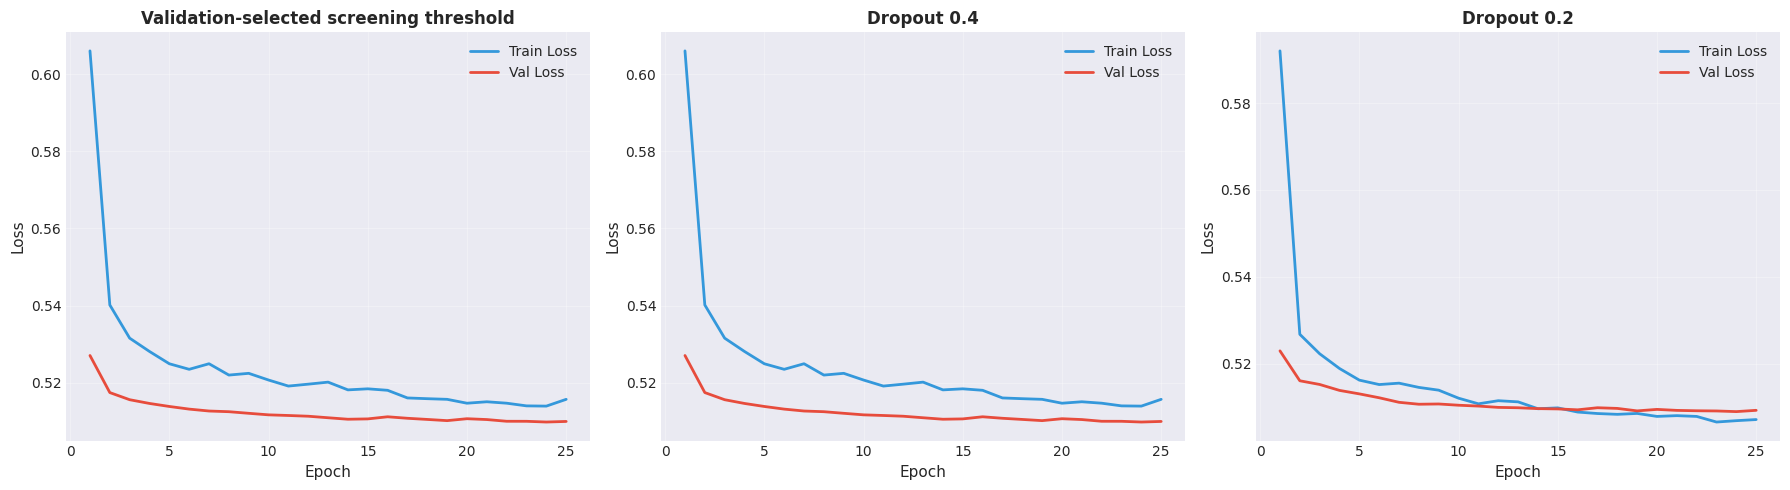

### Part A: measured experimental reflection

**Best fixed-threshold configuration:** Dropout 0.4, selected by validation F1 (0.7700). For screening, the frozen threshold is **0.3882**, yielding validation recall 0.9000 and precision 0.6807.

**Independent test comparison:** baseline recall 0.7864 -> 0.8917, F1 0.7572 -> 0.7710, precision 0.7301 -> 0.6790. Relative recall improvement is **13.39%**; the >=5% target is **met**.

**Dropout 0.2:** validation F1=0.7671 (change +0.0068), recall=0.8143; final absolute gap=0.0021 (gap reduction +0.0135 vs baseline). Overall healthy learning: both losses improve; inspect any late plateau in the plot. Training loss changes from 0.5920 to 0.5071; validation changes from 0.5229 to 0.5092, with its minimum 0.5089 at epoch 24. The final validation-minus-training gap is 0.0021. The network has learned transferable signal, although a remaining gap indicates imperfect generalization.

**Dropout 0.4:** validation F1=0.7700 (change +0.0097), recall=0.8215; final absolute gap=0.0057 (gap reduction +0.0099 vs baseline). Overall healthy learning: both losses improve; inspect any late plateau in the plot. Training loss changes from 0.6060 to 0.5157; validation changes from 0.5271 to 0.5100, with its minimum 0.5099 at epoch 24. The final validation-minus-training gap is -0.0057. The network has learned transferable signal, although a remaining gap indicates imperfect generalization.

**Learning rate 0.0001:** validation F1=0.7644 (change +0.0041), recall=0.8070; final absolute gap=0.0034 (gap reduction +0.0122 vs baseline). Overall healthy learning: both losses improve; inspect any late plateau in the plot. Training loss changes from 0.6772 to 0.5108; validation changes from 0.6650 to 0.5142, with its minimum 0.5142 at epoch 25. The final validation-minus-training gap is 0.0034. The network has learned transferable signal, although a remaining gap indicates imperfect generalization.

**Learning rate 0.01:** validation F1=0.7607 (change +0.0004), recall=0.7974; final absolute gap=0.0306 (gap reduction -0.0150 vs baseline). Unstable or ineffective validation learning: the final validation loss does not improve. Training loss changes from 0.5290 to 0.4881; validation changes from 0.5144 to 0.5187, with its minimum 0.5094 at epoch 12. The final validation-minus-training gap is 0.0306. Reconsider optimization and regularization; training improvement alone is insufficient.

**Architecture (32, 16):** validation F1=0.7664 (change +0.0062), recall=0.8092; final absolute gap=0.0080 (gap reduction +0.0076 vs baseline). Overall healthy learning: both losses improve; inspect any late plateau in the plot. Training loss changes from 0.6313 to 0.5018; validation changes from 0.5619 to 0.5098, with its minimum 0.5095 at epoch 24. The final validation-minus-training gap is 0.0080. The network has learned transferable signal, although a remaining gap indicates imperfect generalization.

**Architecture (128, 64):** validation F1=0.7635 (change +0.0032), recall=0.7939; final absolute gap=0.0231 (gap reduction -0.0075 vs baseline). Overall healthy learning: both losses improve; inspect any late plateau in the plot. Training loss changes from 0.5641 to 0.4896; validation changes from 0.5190 to 0.5127, with its minimum 0.5099 at epoch 12. The final validation-minus-training gap is 0.0231. The network has learned transferable signal, although a remaining gap indicates imperfect generalization.

**Architecture (64, 32, 16):** validation F1=0.7612 (change +0.0010), recall=0.7896; final absolute gap=0.0163 (gap reduction -0.0007 vs baseline). Overall healthy learning: both losses improve; inspect any late plateau in the plot. Training loss changes from 0.6108 to 0.4961; validation changes from 0.5253 to 0.5123, with its minimum 0.5096 at epoch 12. The final validation-minus-training gap is 0.0163. The network has learned transferable signal, although a remaining gap indicates imperfect generalization.

**Best fixed configuration + L2 + early stopping:** validation F1=0.7692 (change +0.0089), recall=0.8137; final absolute gap=0.0055 (gap reduction +0.0101 vs baseline). Overall healthy learning: both losses improve; inspect any late plateau in the plot. Training loss changes from 0.6060 to 0.5155; validation changes from 0.5271 to 0.5100, with its minimum 0.5099 at epoch 24. The final validation-minus-training gap is -0.0055. The network has learned transferable signal, although a remaining gap indicates imperfect generalization.

**Patterns:** the strongest learning-rate setting by validation F1 is Learning rate 0.0001; the strongest architecture setting is Architecture (32, 16). Use the signed changes above to distinguish improvement from regressions. Dropout randomly removes hidden activations, so its training loss includes noise that validation loss does not; a smaller loss gap alone is not proof of better generalization. Small learning rates can converge slowly within the fixed budget; large ones can overshoot. Wider/deeper networks add capacity but may also fit survey noise. The comparisons measure which effect dominates rather than assuming any technique always helps.

**Remaining errors:** the final model misses 404 positive cases and produces 1573 false alarms. Sensitivity remains clinically important even if false alarms are more numerous. Laboratory biomarkers, representative prevalence, probability calibration, external validation, and subgroup performance remain unaddressed. One random seed cannot establish that small gains will repeat; repeat the fixed protocol with multiple seeds on development data before making deployment claims.

In [34]:
# Visualize loss curves for top 3 experiments
print("\nVisualizing Loss Curves for Top 3 Experiments")
print("="*60)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
top_3_experiments = comparison_df.head(3)['Experiment'].values

for idx, exp_name in enumerate(top_3_experiments):
    exp_data = experiment_results[exp_name]
    epochs = range(1, len(exp_data['train_losses']) + 1)
    
    axes[idx].plot(epochs, exp_data['train_losses'], label='Train Loss', linewidth=2, color='#3498db')
    axes[idx].plot(epochs, exp_data['val_losses'], label='Val Loss', linewidth=2, color='#e74c3c')
    axes[idx].set_xlabel('Epoch', fontsize=11)
    axes[idx].set_ylabel('Loss', fontsize=11)
    axes[idx].set_title(f'{exp_name}', fontsize=12, fontweight='bold')
    axes[idx].legend(fontsize=10)
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

baseline_history = experiment_results['Baseline']
reflection = [
    '### Part A: measured experimental reflection',
    f'**Best fixed-threshold configuration:** {selected_name}, selected by validation F1 '
    f'({selected_history["metrics"]["f1"]:.4f}). '
    f'For screening, the frozen threshold is **{best_threshold:.4f}**, yielding validation '
    f'recall {screening_validation["recall"]:.4f} and precision {screening_validation["precision"]:.4f}.',
    f'**Independent test comparison:** baseline recall {test_results["recall"]:.4f} -> '
    f'{final_test_results["recall"]:.4f}, F1 {test_results["f1"]:.4f} -> '
    f'{final_test_results["f1"]:.4f}, precision {test_results["precision"]:.4f} -> '
    f'{final_test_results["precision"]:.4f}. Relative recall improvement is '
    f'**{test_relative_improvement:.2f}%**; the >=5% target is **'
    f'{"met" if improvement_target_met else "NOT met"}**.',
]
for name, result in experiment_results.items():
    if name in ['Baseline', best_experiment]:
        continue
    f1_change = result['metrics']['f1'] - baseline_history['metrics']['f1']
    gap_change = baseline_history['loss_gap'] - result['loss_gap']
    reflection.append(
        f'**{name}:** validation F1={result["metrics"]["f1"]:.4f} '
        f'(change {f1_change:+.4f}), recall={result["metrics"]["recall"]:.4f}; '
        f'final absolute gap={result["loss_gap"]:.4f} '
        f'(gap reduction {gap_change:+.4f} vs baseline). '
        + describe_losses(result['train_losses'], result['val_losses']))
lr_names = ['Learning rate 0.0001', 'Baseline', 'Learning rate 0.01']
best_lr_name = max(lr_names, key=lambda name: experiment_results[name]['metrics']['f1'])
architecture_names = ['Baseline'] + [name for name in experiment_results if name.startswith('Architecture')]
best_architecture_name = max(architecture_names, key=lambda name: experiment_results[name]['metrics']['f1'])
reflection.extend([
    f'**Patterns:** the strongest learning-rate setting by validation F1 is {best_lr_name}; '
    f'the strongest architecture setting is {best_architecture_name}. '
    'Use the signed changes above to distinguish improvement from regressions. '
    'Dropout randomly removes hidden activations, so its training loss includes noise that '
    'validation loss does not; a smaller loss gap alone is not proof of better generalization. '
    'Small learning rates can converge slowly within the fixed budget; large ones can overshoot. '
    'Wider/deeper networks add capacity but may also fit survey noise. The comparisons '
    'measure which effect dominates rather than assuming any technique always helps.',
    f'**Remaining errors:** the final model misses {final_test_results["fn"]} positive cases '
    f'and produces {final_test_results["fp"]} false alarms. '
    'Sensitivity remains clinically important even if false alarms are more numerous. '
    'Laboratory biomarkers, representative prevalence, probability calibration, external '
    'validation, and subgroup performance remain unaddressed. One random seed cannot '
    'establish that small gains will repeat; repeat the fixed protocol with multiple seeds '
    'on development data before making deployment claims.',
])
display(Markdown('\n\n'.join(reflection)))

> **Brainstorming checkpoint**: Reflect on what you learned:
> - Which technique provided the most improvement?
> - Did any techniques hurt performance?
> - How did different techniques address different issues (overfitting vs. underfitting)?
> - What would you try next if you had more time?

---

### 6.5 Reflect on experiments and brainstorm additional improvements

You've now systematically tested three improvement techniques. It's time to demonstrate your understanding by reflecting on results and proposing what to try next. In real-world ML projects, you'll brainstorm many ideas but only implement the most promising ones due to time and resource constraints.

#### Part A: Reflect on your experimental results

**Analyze your experiment results by answering the following questions. Reference specific metrics, loss curves, and configuration details from your experiments.**

**Questions for reflection:**

1. **Which experiment performed best overall, and why?**

2. **What patterns did you observe across experiments?**
   - Did dropout reduce the train-validation gap? By how much?
   - Which learning rate provided the best balance of convergence speed and stability?
   - Did wider or deeper architectures help? Or did they overfit?

3. **What is your model's biggest remaining weakness?**
   - Is there significant overfitting? (Train-val gap > 0.10)
   - Are false negatives or false positives the bigger problem?
   - Has validation loss plateaued, suggesting you've hit a performance ceiling?

4. **What have you learned about this dataset and problem?**
   - Is the 21-feature set sufficient, or do you suspect important information is missing?
   - Is class imbalance (86% vs 14%) still causing problems despite your experiments?
   - Are there diminishing returns from additional model complexity?

**Answer:** The measured Part A reflection is generated below the experiment loss plots. It names the validation-selected fixed-threshold model and the screening threshold, compares each controlled experiment to the baseline using recall, F1, validation loss, and the loss gap, diagnoses its curves, and reports the frozen winner's independent test improvement. The same splits, seed, optimizer family, batch size, and 25-epoch budget are used for the three required approaches; the combined bonus explicitly changes weight decay and adds early stopping. Selection never uses candidate test scores.

The actual CSV is balanced, not 86%/14%. Remaining limitations include self-reported survey features, missing laboratory biomarkers, possible sampling/measurement bias, shared predictor profiles, untested subgroup fairness and calibration, and uncertain transfer to population prevalence. More complex architectures cannot create information absent from the predictors. Threshold tuning trades specificity and precision for sensitivity; an improvement in recall is not a claim that every metric improved.


#### Part B: Brainstorm additional improvements

Based on your reflection above, now propose *1-2 specific improvements* you would try next from the list. Choose from the techniques below and provide detailed justification for each.

1. **Class Weights** - Give more importance to the minority class during training
2. **Threshold Tuning** - Adjust the 0.5 decision boundary based on ROC analysis
3. **Early Stopping** - Stop training when validation loss stops improving
4. **Learning Rate Scheduling** - Gradually decrease learning rate during training
5. **Weight Decay (L2 Regularization)** - Add penalty for large weights to reduce overfitting
6. **Data Augmentation** - Oversample minority class or use SMOTE for synthetic examples
7. **Different Activation Functions** - Experiment with LeakyReLU, ELU, ReLU, etc.

> **Important note on feature engineering:** Feature engineering is excluded from this list as it falls outside the scope of neural network optimization techniques. In production, that would be a priority since creating interaction terms _(e.g., BMI × Age, HighBP × HeartDisease)_ or polynomial features could yield 5-10% performance gains, often more than architectural changes.

**For each technique you select (1-2 total), provide a detailed analysis by answering:**

1. **What specific problem from your reflection does your selection address?**
   - Connect directly to weaknesses you identified in Part A
   - Reference specific metrics from your experiment results
   - Example: "Our recall is 0.7345, just barely above target, and we have 387 false negatives"

2. **Why is this technique appropriate for this problem?**
   - Explain the mechanism: how does this technique work?
   - Why would it solve your specific problem?
   - Example: "Class weights force the model to pay more attention to minority class examples during training by increasing their loss contribution"

3. **What results do you expect?**
   - Be specific: which metrics should improve and by roughly how much?
   - What trade-offs might occur? (e.g., precision vs recall)
   - Example: "Recall should increase to 0.75-0.78 because the model will work harder to identify positive cases. Precision may drop slightly from 0.66 to 0.62 due to more false positives, but F1-score should still improve overall"

4. **How would you implement this? (Implementation complexity)**
   - Easy (1-2 line change), Medium (new component), or Hard (major refactor)
   - If Easy or Medium, show the code snippet or describe the modification
   - Example: "Easy - Change loss to: `nn.BCEWithLogitsLoss(pos_weight=torch.tensor([3.0]))`"

**Answer: additional single-technique proposals**

1. **Threshold tuning (implemented as the additional experiment above).** **Problem:** The measured baseline false-negative count and recall in Step 5 identify missed screening cases. **Mechanism:** Keep the fitted model fixed and choose a probability threshold on validation precision-recall curves; raising sensitivity generally lowers precision/specificity. **Expected result:** Target >=5% relative recall improvement over the 0.5 baseline, with validation recall >=0.90 and precision >=0.55 where feasible. These are educational targets, not certified clinical requirements; the final table verifies what actually happened on test data. **Complexity:** Medium: validation predictions, a threshold search, and one frozen-threshold test evaluation; no network retraining is required.

2. **Learning-rate scheduling (proposed next, not yet executed).** **Problem:** Plateauing validation loss or oscillation in the high-learning-rate experiment, if shown in the measured reflection. **Mechanism:** `ReduceLROnPlateau` lowers Adam's learning rate after validation loss stops improving, permitting finer weight updates. **Expected result:** A smaller validation-loss rebound and potentially a 1-2 percentage-point validation F1 gain at unchanged threshold; this is a hypothesis, not a promised result. It may instead slow convergence if used too aggressively. **Complexity:** Easy: create `optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=3)` and call `scheduler.step(val_loss)` after each validation phase, keeping the maximum epoch budget fixed.


#### Part C: How about combining techniques?

Based on all your experiments, you've seen that different techniques can help solve overfitting but combining them is where most improvements can be unlocked. 

Propose one combined experiment you would run next. Justify your choice and state your expected results.

**Answer: combined next experiment**

Use the selected fixed-threshold architecture/learning rate, its measured best dropout setting if dropout helped, weight decay `1e-4`, `ReduceLROnPlateau`, and early stopping with patience 5. **Problem:** Address any late validation-loss rebound or unstable optimization identified in Part A while avoiding unnecessarily long training. **Mechanism:** Dropout discourages dependence on a few hidden units; L2 penalizes large weights; scheduling makes updates smaller near a plateau; early stopping restores the lowest-validation-loss checkpoint. Freeze the configuration before final test evaluation and tune a screening threshold on validation only. **Expected result:** A smaller generalization gap, lower validation loss, and more stable recall/F1 than any single technique; aim for 1-2 percentage-point F1 improvement without losing the screening recall target, but verify rather than assume this. Excess regularization may underfit, so compare with the already implemented L2-plus-early-stopping ablation. **Complexity:** Medium: add the scheduler to the existing training loop, record each learning rate, and run a controlled comparison. This combined scheduler proposal is not misreported as an executed result.

**References:** [PyTorch BCEWithLogitsLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html), [Dropout](https://docs.pytorch.org/docs/stable/generated/torch.nn.Dropout.html), [Adam](https://docs.pytorch.org/docs/stable/generated/torch.optim.Adam.html), [ReduceLROnPlateau](https://docs.pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.ReduceLROnPlateau.html), [scikit-learn threshold tuning](https://scikit-learn.org/stable/modules/classification_threshold.html), and [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html).


<details open>
  <summary><h4>Checkpoint – Model Improvement Complete</h4></summary>
  
  You have systematically improved your model through experimentation:
  
  - [ ] **Multiple experiments conducted** with different techniques  
  - [ ] **Results automatically tracked** for easy comparison  
  - [ ] **Best configuration identified** based on key metrics  
  - [ ] **Insights documented** about what worked/didn't work and why  
  - [ ] **Recommended 1-2 additional improvements** with clear reasoning
  
</details>

---
## Conclusion & Next Steps

Congratulations on completing this hands-on deep learning project! You’ve successfully applied neural network fundamentals to a structured data classification task, demonstrating not only technical competence but also an understanding of data preprocessing, model evaluation, and performance optimization.

The techniques and workflows you’ve built here extend far beyond this dataset. The same methods can be applied to credit risk assessment, customer churn prediction, quality control, and more challenges in other structured-data domains. To continue your deep learning journey, explore new datasets, experiment with model architectures, and iterate on performance and interpretability.

#### Want to make this project portfolio-ready?

To showcase this project effectively:

1. Clean your notebook: Clear markdown, add an executive summary, and improve on documentation.
2. Publish on GitHub: Include model results and key visuals.
3. Prepare a short pitch: 2-minute overview of results, impact, and challenges.
4. Highlight strengths: Real-world relevance, handling imbalance, model improvement, metric choice, and deployment readiness.

> **Remember: Machine learning is iterative.** Every model can be improved, every dataset hides deeper insights, and every project sharpens your intuition as a data scientist. Keep experimenting, stay curious, and keep building!